# Simplified NextBrain labels vs NextBrain segmentation

For each synthetic case (1-5) we compare two label maps that live on **the same 0.4 mm grid** (same shape and affine, checked in the code):

| | file | what it is |
|---|---|---|
| **reference** (`ref`) | `data/outputs/simplifiednxb/labels/case-N.nii.gz` | the generator's label map after `allennxb_to_simplifiednxb.py` (71 labels removed and filled with the nearest region) |
| **prediction** (`pred`) | `.../deterministic/segmentation_nextbrain/case-N.nii.gz/seg.<side>_resampled.nii.gz` | NextBrain (`mri_histo_atlas_segment_fireants`) run on the synthetic image generated from that label map, resampled back to the input grid |

Note: the case reports of the simplification (`case-N_report.json`) show `removed_voxels = 0` for every case: the generator's label maps already contain none of the 71 removed labels, so the reference is identical to the label map the synthetic image was generated from.

Cases 1-3 are right hemispheres and cases 4-5 left hemispheres. NextBrain names the cortex `ctx-rh-*` (2001-2035) for both sides, and so does the reference.

What is computed (in `compare_segmentations.py`, from one sparse confusion table `(ref label, pred label, voxels)` per case):

* **Dice** per label, and per tree node after merging labels at the leaf level and at levels 1-3 of the simplified tree;
* **Volumes** (mm³) per label in both maps and the relative difference `(pred - ref) / ref`;
* **Presence**: labels only in `ref` and labels only in `pred`;
* **Position**: centroid of every label in both maps (world mm), its displacement, and where the voxels of each label go (`ref -> pred`) and come from (`pred -> ref`). These give the *misplaced* labels.

Every table is saved in `data/outputs/simplifiednxb/metrics/`.

In [1]:
import json
from concurrent.futures import ProcessPoolExecutor

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import nibabel as nib
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

import compare_segmentations as cs

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 45)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

METRICS = cs.METRICS_DIR
METRICS.mkdir(parents=True, exist_ok=True)
NAMES = cs.label_names()

# colours: reference = blue, prediction = orange (also used for contours)
C_REF, C_PRED = '#2a78d6', '#eb6834'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6})

## 1. Compute the metrics (5 cases in parallel) and save them

In [2]:
with ProcessPoolExecutor(len(cs.CASES)) as ex:
    results = list(ex.map(cs.compare_case, cs.CASES))

summary = pd.DataFrame([r['summary'] for r in results]).set_index('case')
labels = cs.flag_misplaced(pd.concat([r['labels'] for r in results], ignore_index=True))
levels = pd.concat([r['levels'] for r in results], ignore_index=True).rename(columns={'label': 'node'})
conf = pd.concat([r['confusion'] for r in results], ignore_index=True)
swaps = cs.swaps(labels)

presence = labels[labels.presence != 'both'][
    ['case', 'label', 'name', 'presence', 'vol_ref_mm3', 'vol_pred_mm3',
     'ref_to_pred_name', 'ref_to_pred_frac', 'pred_from_ref_name', 'pred_from_ref_frac']]
misplaced = labels[labels.misplaced].sort_values(['case', 'vol_ref_mm3'], ascending=[True, False])

# wide per-label tables (one column per case)
dice_wide = labels.pivot_table(index=['label', 'name'], columns='case', values='dice')
vol_wide = labels.pivot_table(index=['label', 'name'], columns='case', values=['vol_ref_mm3', 'vol_pred_mm3'])

summary.to_csv(METRICS / 'summary.csv')
labels.to_csv(METRICS / 'labels_per_case.csv', index=False)
levels.to_csv(METRICS / 'tree_levels_dice.csv', index=False)
conf.to_csv(METRICS / 'confusion_pairs.csv', index=False)
presence.to_csv(METRICS / 'presence_differences.csv', index=False)
misplaced.to_csv(METRICS / 'misplaced_labels.csv', index=False)
swaps.to_csv(METRICS / 'mutual_swaps.csv', index=False)
dice_wide.to_csv(METRICS / 'dice_label_x_case.csv')
vol_wide.to_csv(METRICS / 'volume_label_x_case.csv')
print(sorted(p.name for p in METRICS.iterdir()))

['confusion_pairs.csv', 'dice_label_x_case.csv', 'labels_mean_over_cases.csv', 'labels_per_case.csv', 'misplaced_labels.csv', 'misplaced_over_cases.csv', 'mutual_swaps.csv', 'presence_differences.csv', 'presence_differences_over_cases.csv', 'summary.csv', 'top_confusions.csv', 'tree_levels_dice.csv', 'volume_differences_over_cases.csv', 'volume_label_x_case.csv']


Saved files:

| file | content |
|---|---|
| `summary.csv` | one row per case: number of labels, labels only in one map, brain-mask dice, voxel agreement, mean/median/volume-weighted dice |
| `labels_per_case.csv` | one row per (case, label): voxels, volumes, dice, centroids, displacement, dominant label in the other map, misplacement flags |
| `tree_levels_dice.csv` | dice/volumes per tree node (`level` = `leaf`, 1, 2, 3) |
| `confusion_pairs.csv` | sparse confusion table `(case, ref, pred, n voxels)` (background-background excluded) |
| `presence_differences.csv` | labels present in only one of the maps |
| `misplaced_labels.csv` | labels present in both maps but not where they should be (definition in section 6) |
| `mutual_swaps.csv` | pairs of labels that exchange their positions |
| `dice_label_x_case.csv`, `volume_label_x_case.csv` | label x case tables |

## 2. Global summary per case

In [3]:
display(summary)

,side,n_labels_ref,n_labels_pred,n_only_ref,n_only_pred,brain_dice,voxel_agreement_fg,mean_dice_shared,median_dice_shared,vol_weighted_dice
case,,,,,,,,,,
1,right,262,258,5,1,0.948,0.760,0.265,0.151,0.800
2,right,260,256,7,3,0.949,0.745,0.281,0.199,0.784
3,right,261,259,4,2,0.944,0.745,0.303,0.233,0.787
4,left,260,258,5,3,0.958,0.755,0.260,0.161,0.787
5,left,262,258,5,1,0.955,0.777,0.308,0.247,0.812


* `brain_dice` - dice of the foreground masks (`ref > 0` vs `pred > 0`): the brain outline.
* `voxel_agreement_fg` - fraction of the foreground voxels (of either map) with the same label.
* `mean_dice_shared` / `median_dice_shared` - over the labels present in both maps (each label weighs the same, so
  the many tiny nuclei pull them down).
* `vol_weighted_dice` - dice weighted by label size (dominated by the white matter and the cortex).

## 3. Dice

### 3.1 Dice by tree level

Labels are merged into their tree node before computing dice. `leaf` merges labels that share one leaf
(the only one is `white_matter_of_hindbrain = [846, 611]`, see section 5). Level 1 = tissue classes, level 2 = main subdivisions.

count                      mean                         median                        
case      1    2    3    4    5     1     2     3     4     5      1     2     3     4     5
level                                                                                       
1         7    7    7    7    7 0.728 0.791 0.770 0.787 0.757  0.837 0.872 0.893 0.887 0.867
2        19   19   19   19   19 0.379 0.456 0.434 0.445 0.472  0.237 0.437 0.395 0.382 0.428
3        52   52   52   52   52 0.310 0.367 0.362 0.341 0.385  0.127 0.343 0.254 0.213 0.265
leaf    262  262  262  262  262 0.263 0.275 0.300 0.256 0.305  0.150 0.184 0.224 0.154 0.244

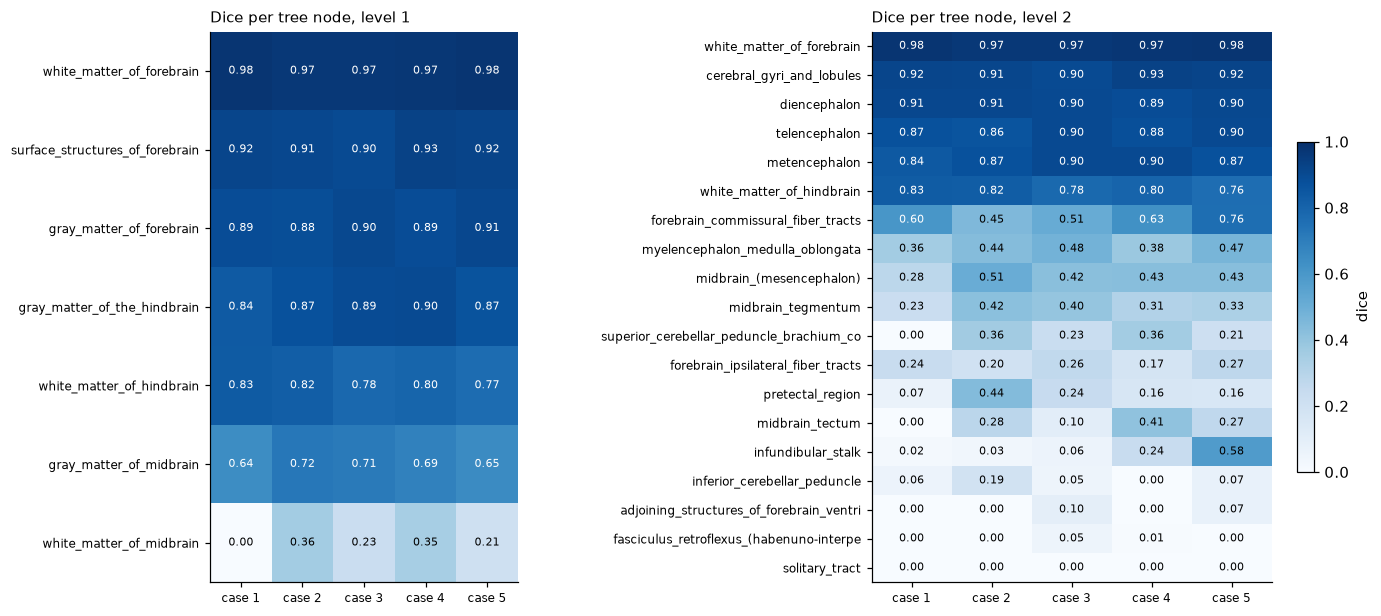

In [4]:
lv = levels.copy()
lv['level'] = lv['level'].astype(str)
lvl_summary = lv.groupby(['level', 'case']).dice.agg(['count', 'mean', 'median']).unstack('case')
display(lvl_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [1, 1.3], 'wspace': 1.0})
for ax, lev in zip(axes, ['1', '2']):
    t = lv[lv.level == lev].pivot_table(index='node', columns='case', values='dice')
    t = t.loc[t.mean(axis=1).sort_values(ascending=False).index]
    im = ax.imshow(t.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set_yticks(range(len(t)), [n.replace('_l1', '').replace('_l2', '')[:40] for n in t.index], fontsize=8)
    ax.set_xticks(range(t.shape[1]), [f'case {c}' for c in t.columns], fontsize=8)
    ax.grid(False)
    for (i, j), v in np.ndenumerate(t.values):
        if np.isfinite(v):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7, color='white' if v > 0.6 else 'black')
    ax.set_title(f'Dice per tree node, level {lev}', fontsize=10, loc='left')
fig.colorbar(im, ax=axes, shrink=0.6, label='dice', pad=0.02)
plt.show()

### 3.2 Dice per label vs structure size

Each dot is one (case, label) present in both maps. Dice depends strongly on size: at 0.4 mm, a 10 mm³ nucleus has ~150
voxels, so a 1 mm boundary error already removes most of the overlap.

ref volume (mm3),<10,10-100,100-1k,1k-10k,>10k
count,219.000,529.000,320.000,134.000,77.000
median,0.012,0.107,0.330,0.755,0.791
mean,0.074,0.160,0.348,0.708,0.724


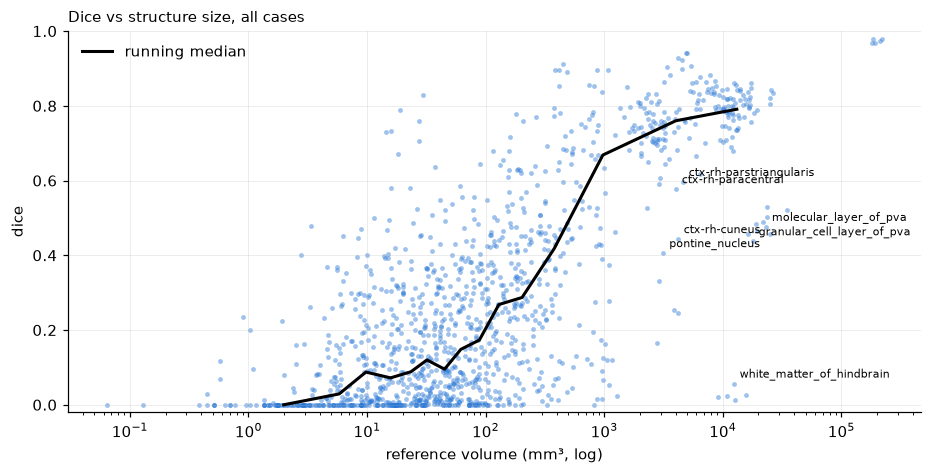

In [5]:
b = labels[labels.presence == 'both']
bins = pd.cut(b.vol_ref_mm3, [0, 10, 100, 1000, 1e4, 1e7],
              labels=['<10', '10-100', '100-1k', '1k-10k', '>10k'])
display(b.groupby(bins, observed=True).dice.agg(['count', 'median', 'mean']).rename_axis('ref volume (mm3)').T)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(b.vol_ref_mm3, b.dice, s=10, color=C_REF, alpha=0.45, linewidths=0)
med = b.groupby(pd.qcut(np.log10(b.vol_ref_mm3), 15)).agg(v=('vol_ref_mm3', 'median'), d=('dice', 'median'))
ax.plot(med.v, med.d, color='black', lw=2, label='running median')
for _, r in b[(b.vol_ref_mm3 > 3000) & (b.dice < 0.6)].drop_duplicates('label').iterrows():
    ax.annotate(r['name'], (r.vol_ref_mm3, r.dice), fontsize=7, xytext=(4, 4), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('reference volume (mm³, log)'); ax.set_ylabel('dice'); ax.set_ylim(-0.02, 1)
ax.legend(frameon=False, loc='upper left'); ax.set_title('Dice vs structure size, all cases', loc='left', fontsize=10)
plt.show()

### 3.3 Best and worst labels (mean over the 5 cases, labels present in the reference)

In [6]:
agg = (labels[labels.vox_ref > 0].groupby(['label', 'name'])
       .agg(n_cases=('case', 'size'), dice_mean=('dice', 'mean'), dice_min=('dice', 'min'), dice_max=('dice', 'max'),
            vol_ref=('vol_ref_mm3', 'mean'), vol_pred=('vol_pred_mm3', 'mean'),
            shift_mm=('centroid_dist_mm', 'mean'))
       .sort_values('dice_mean'))
agg.to_csv(METRICS / 'labels_mean_over_cases.csv')
display(Markdown('**Worst 25**')); display(agg.head(25))
display(Markdown('**Worst 25 among labels > 100 mm³** (size alone does not explain these)')); display(agg[agg.vol_ref > 100].head(25))
display(Markdown('**Best 15**')); display(agg.tail(15)[::-1])

**Worst 25**

,,n_cases,dice_mean,dice_min,dice_max,vol_ref,vol_pred,shift_mm
label,name,,,,,,,
687,solitary_tract,5,0.000,0.000,0.000,20.634,0.090,11.852
569,stratum_oriens_of_caudal_ca2,5,0.000,0.000,0.000,1.600,0.026,3.490
442,basal_ventral_medial_nucleus,5,0.000,0.000,0.000,2.611,0.154,3.953
443,dorsal_division_of_central_lateral_nucleus,4,0.000,0.000,0.000,1.776,0.240,2.189
506,pineal_body,5,0.000,0.000,0.000,29.670,0.090,5.034
451,interstitial_nucleus_of_cajal,5,0.000,0.000,0.000,2.931,0.000,NaN
365,granular_layer_of_uncal_dentate_gyrus,5,0.000,0.000,0.000,3.405,0.230,3.609
342,stratum_oriens_of_uncal_ca1,5,0.000,0.000,0.000,17.331,1.485,2.353
411,stratum_oriens_of_rostral_ca2,5,0.000,0.000,0.000,6.310,0.038,8.114


**Worst 25 among labels > 100 mm³** (size alone does not explain these)

,,n_cases,dice_mean,dice_min,dice_max,vol_ref,vol_pred,shift_mm
label,name,,,,,,,
654,inferior_olive__principal_nucleus,5,0.006,0.000,0.017,159.949,4.147,5.748
381,ventral_subdivision_of_vlc,5,0.011,0.000,0.033,120.461,96.512,4.607
184,stria_terminalis,5,0.018,0.010,0.026,314.842,82.189,9.660
611,white_matter_of_hindbrain,5,0.028,0.012,0.056,12184.602,1911.642,24.498
394,rostral_division_of_ventral_posterior_lateral_nucleus,5,0.030,0.000,0.083,146.726,89.510,3.938
68,septum_pellucidum,5,0.034,0.000,0.096,248.986,7.309,4.778
580,pons,5,0.071,0.024,0.119,1096.678,2067.072,8.825
697,inferior_cerebellar_peduncle,5,0.074,0.000,0.192,242.483,61.747,4.893
354,alveus,5,0.080,0.015,0.125,917.683,565.658,8.173


**Best 15**

,,n_cases,dice_mean,dice_min,dice_max,vol_ref,vol_pred,shift_mm
label,name,,,,,,,
7,white_matter_of_forebrain,5,0.973,0.967,0.979,198015.459,198926.089,0.206
79,putamen,5,0.927,0.906,0.941,4790.682,5173.325,0.496
206,internal_segment_of_globus_pallidus,5,0.889,0.853,0.911,430.438,476.365,0.593
48,head_of_caudate,5,0.876,0.831,0.904,3434.509,3297.216,1.075
2035,ctx-rh-insula,5,0.869,0.861,0.883,6566.221,6044.557,0.761
119,external_segment_of_globus_pallidus,5,0.868,0.836,0.897,896.435,970.086,0.468
2012,ctx-rh-lateralorbitofrontal,5,0.846,0.835,0.867,8393.280,7604.416,1.171
2024,ctx-rh-precentral,5,0.822,0.774,0.861,16163.828,14821.786,1.144
2028,ctx-rh-superiorfrontal,5,0.818,0.790,0.841,24305.537,20958.247,1.713


## 4. Volumes

Each panel compares the volume of every label in the two maps (log-log, the diagonal is equal volume). Points far from
the diagonal are labels that NextBrain makes much larger or smaller than the reference; labels present in only one map
are drawn on the border of the panel.

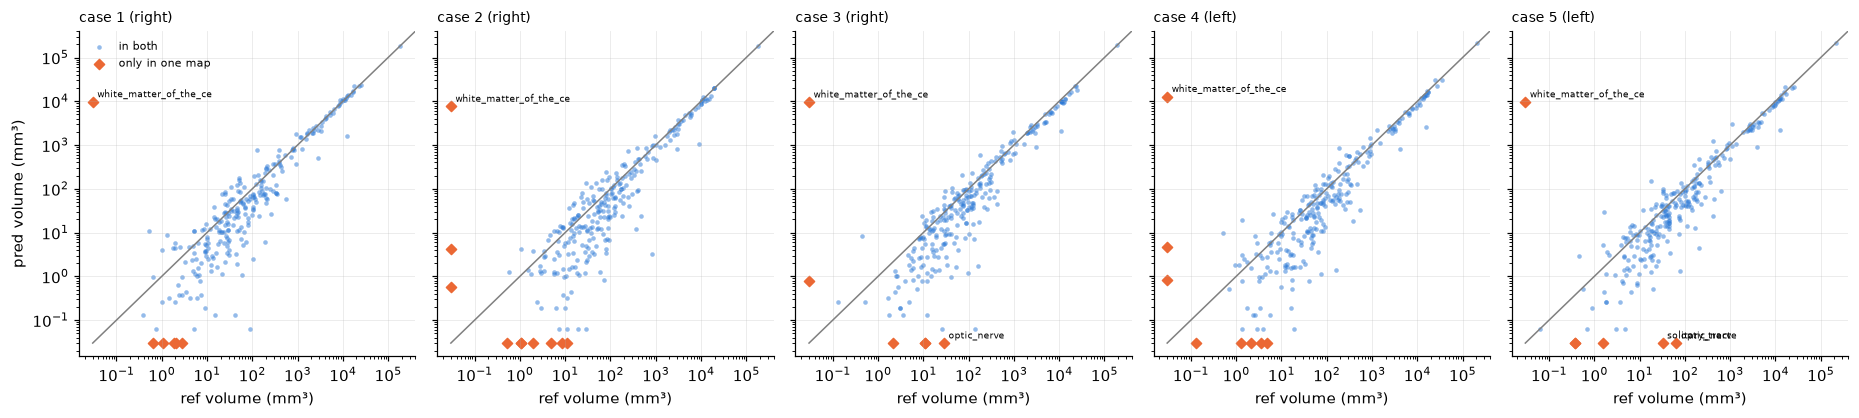

**Total labelled volume per case**

,vol_ref_mm3,vol_pred_mm3,rel_diff
case,,,
1,518241.945,518548.249,0.001
2,498976.728,473868.183,-0.050
3,544375.770,495588.568,-0.090
4,620209.821,580963.676,-0.063
5,571753.371,537664.346,-0.060


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.9), sharex=True, sharey=True)
lo, hi = 0.03, 4e5
for ax, (case, d) in zip(axes, labels.groupby('case')):
    x, y = d.vol_ref_mm3.clip(lower=lo), d.vol_pred_mm3.clip(lower=lo)
    one = d.presence != 'both'
    ax.plot([lo, hi], [lo, hi], color='0.5', lw=1)
    ax.scatter(x[~one], y[~one], s=9, color=C_REF, alpha=0.5, linewidths=0, label='in both')
    ax.scatter(x[one], y[one], s=22, color=C_PRED, marker='D', label='only in one map')
    for _, r in d[one & (np.maximum(d.vol_ref_mm3, d.vol_pred_mm3) > 20)].iterrows():
        ax.annotate(r['name'][:22], (max(r.vol_ref_mm3, lo), max(r.vol_pred_mm3, lo)), fontsize=6,
                    xytext=(3, 3), textcoords='offset points')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lo / 2, hi); ax.set_ylim(lo / 2, hi)
    ax.set_title(f'case {case} ({summary.side[case]})', fontsize=9, loc='left'); ax.set_xlabel('ref volume (mm³)')
axes[0].set_ylabel('pred volume (mm³)'); axes[0].legend(frameon=False, fontsize=7, loc='upper left')
plt.tight_layout(); plt.show()

tot = labels.groupby('case')[['vol_ref_mm3', 'vol_pred_mm3']].sum()
tot['rel_diff'] = tot.vol_pred_mm3 / tot.vol_ref_mm3 - 1
display(Markdown('**Total labelled volume per case**')); display(tot)

**Largest relative volume differences (labels > 50 mm³, mean over cases; `rel_diff` = pred/ref - 1)**

,,vol_ref,vol_pred,rel_diff_mean,rel_diff_min,rel_diff_max,dice_mean,n_cases
label,name,,,,,,,
454,anterior_nucleus_of_pulvinar,204.339,635.277,2.386,1.270,5.070,0.320,5
508,medial_nucleus_of_pulvinar,502.605,846.054,1.206,-0.006,3.774,0.545,5
339,stratum_lacunosum-moleculare_of_uncal_ca1,87.066,178.931,1.180,0.169,1.922,0.223,5
506,pineal_body,140.160,0.064,-1.000,-1.000,-1.000,0.000,1
397,medial_division_of_centromedian_nucleus_of_thalamus,94.758,174.477,0.992,0.047,2.213,0.298,5
666,facial_nucleus,76.339,1.126,-0.985,-0.989,-0.982,0.002,5
240,paralaminar_nucleus,52.800,1.600,-0.970,-0.970,-0.970,0.056,1
654,inferior_olive__principal_nucleus,159.949,4.147,-0.968,-0.991,-0.915,0.006,5
114,optic_nerve,91.264,3.424,-0.964,-0.999,-0.928,0.002,2


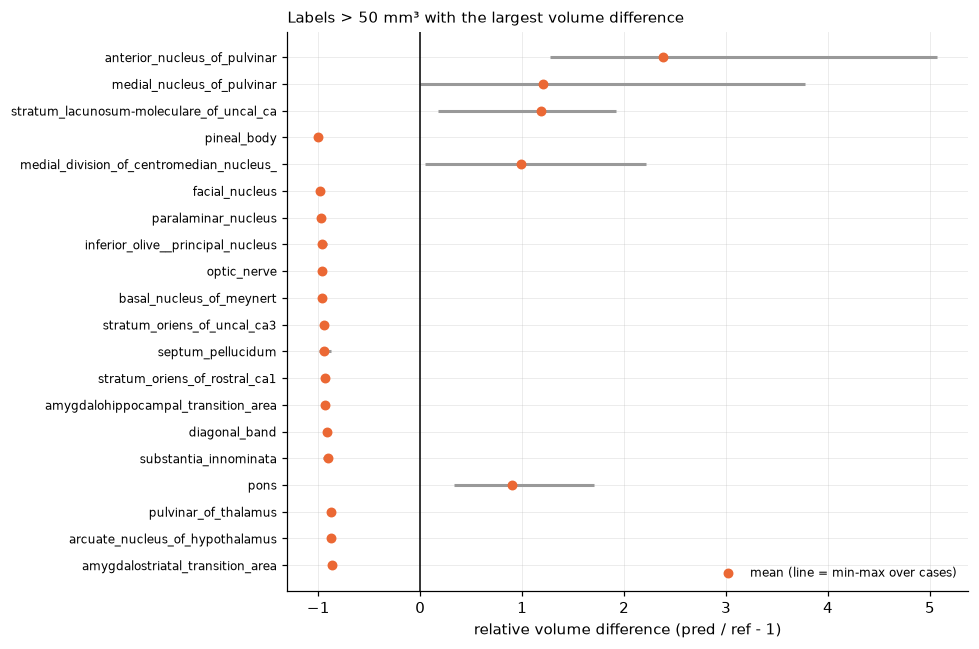

In [8]:
big = labels[(labels.presence == 'both') & (labels.vol_ref_mm3 > 50)]
vd = (big.groupby(['label', 'name'])
      .agg(vol_ref=('vol_ref_mm3', 'mean'), vol_pred=('vol_pred_mm3', 'mean'),
           rel_diff_mean=('vol_diff_rel', 'mean'), rel_diff_min=('vol_diff_rel', 'min'), rel_diff_max=('vol_diff_rel', 'max'),
           dice_mean=('dice', 'mean'), n_cases=('case', 'size'))
      .assign(abs_rel=lambda t: t.rel_diff_mean.abs()).sort_values('abs_rel', ascending=False).drop(columns='abs_rel'))
vd.to_csv(METRICS / 'volume_differences_over_cases.csv')
display(Markdown('**Largest relative volume differences (labels > 50 mm³, mean over cases; `rel_diff` = pred/ref - 1)**'))
display(vd.head(30))

top = vd.head(20)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(top))
ax.hlines(yy, top.rel_diff_min, top.rel_diff_max, color='0.6', lw=2)
ax.scatter(top.rel_diff_mean, yy, color=C_PRED, s=30, zorder=3, label='mean (line = min-max over cases)')
ax.axvline(0, color='black', lw=1)
ax.set_yticks(yy, [n[1][:40] for n in top.index], fontsize=8); ax.set_xlabel('relative volume difference (pred / ref - 1)')
ax.set_title('Labels > 50 mm³ with the largest volume difference', loc='left', fontsize=10)
ax.legend(frameon=False, fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

## 5. Labels present in only one of the maps

`only_ref`: in the simplified reference but never predicted by NextBrain. `only_pred`: predicted by NextBrain but absent
from the reference. `ref_to_pred_name` is the label NextBrain gave to most voxels of an `only_ref` label;
`pred_from_ref_name` is the reference label that most voxels of an `only_pred` label had.

In [9]:
display(presence)

pres = (presence.groupby(['label', 'name', 'presence'])
        .agg(cases=('case', lambda c: ','.join(map(str, c))), vol_ref=('vol_ref_mm3', 'mean'), vol_pred=('vol_pred_mm3', 'mean'),
             goes_to=('ref_to_pred_name', lambda s: s.dropna().mode().iat[0] if s.notna().any() else None),
             comes_from=('pred_from_ref_name', lambda s: s.dropna().mode().iat[0] if s.notna().any() else None))
        .reset_index().sort_values(['presence', 'cases'], key=lambda s: s.str.len() if s.name == 'cases' else s, ascending=[True, False]))
pres.to_csv(METRICS / 'presence_differences_over_cases.csv', index=False)
display(Markdown('**Grouped over cases**')); display(pres)

tree_labels = {l for v in cs.load_tree()['nodes'].values() for l in v['labels']}
lut_ids = {int(l.split()[0]) for l in open(cs.SEG_DIR / 'case-1.nii.gz/lut.txt') if l.strip()}
print('labels in the simplified tree but not in the NextBrain LUT:', {l: NAMES[l] for l in sorted(tree_labels - lut_ids)})
print('labels in the NextBrain LUT but not in the simplified tree:', {l: NAMES[l] for l in sorted(lut_ids - tree_labels)})

,case,label,name,presence,vol_ref_mm3,vol_pred_mm3,ref_to_pred_name,ref_to_pred_frac,pred_from_ref_name,pred_from_ref_frac
197,1,442,basal_ventral_medial_nucleus,only_ref,1.088,0.000,ventral_posterior_medial_nucleus,0.471,NaN,NaN
200,1,451,interstitial_nucleus_of_cajal,only_ref,2.112,0.000,limitans_nucleus,0.424,NaN,NaN
231,1,567,stratum_radiatum_of_caudal_ca2,only_ref,1.856,0.000,stratum_lacunosum-moleculare_of_caudal_ca1,0.414,NaN,NaN
233,1,569,stratum_oriens_of_caudal_ca2,only_ref,0.640,0.000,white_matter_of_forebrain,0.300,NaN,NaN
235,1,572,stratum_lucidum__of_caudal_ca3,only_ref,2.752,0.000,stratum_lacunosum-moleculare_of_caudal_ca2,0.256,NaN,NaN
261,1,846,white_matter_of_the_cerebellum,only_pred,0.000,9745.920,NaN,NaN,white_matter_of_hindbrain,0.970
282,2,160,suprachiasmatic_nucleus,only_ref,0.512,0.000,supraoptic_region_of_hth,0.500,NaN,NaN
443,2,411,stratum_oriens_of_rostral_ca2,only_ref,8.448,0.000,background,0.265,NaN,NaN
461,2,443,dorsal_division_of_central_lateral_nucleus,only_pred,0.000,0.576,NaN,NaN,thalamus,0.556
463,2,451,interstitial_nucleus_of_cajal,only_ref,1.088,0.000,midbrain_(mesencephalon),0.824,NaN,NaN


**Grouped over cases**

,label,name,presence,cases,vol_ref,vol_pred,goes_to,comes_from
17,846,white_matter_of_the_cerebellum,only_pred,"1,2,3,4,5",0.000,9906.061,NaN,white_matter_of_hindbrain
2,209,supraoptic_dicussation,only_pred,4,0.000,0.832,NaN,optic_chiasm
3,375,stratum_oriens_of_uncal_ca3,only_pred,4,0.000,4.736,NaN,stratum_lacunosum-moleculare_of_uncal_ca2
7,443,dorsal_division_of_central_lateral_nucleus,only_pred,2,0.000,0.576,NaN,thalamus
14,578,pulvinar_of_thalamus,only_pred,2,0.000,4.288,NaN,lateral_nucleus_of_pulvinar
16,765,central_gray_of_medulla_oblongata,only_pred,3,0.000,0.768,NaN,myelencephalon_(medulla_oblongata)
9,451,interstitial_nucleus_of_cajal,only_ref,"1,2,3,4,5",2.931,0.000,midbrain_(mesencephalon),NaN
12,569,stratum_oriens_of_caudal_ca2,only_ref,"1,2,3,5",1.360,0.000,white_matter_of_forebrain,NaN
0,114,optic_nerve,only_ref,"3,4,5",32.491,0.000,background,NaN
1,160,suprachiasmatic_nucleus,only_ref,"2,4",0.896,0.000,supraoptic_region_of_hth,NaN


labels in the simplified tree but not in the NextBrain LUT: {3: 'cerebral_gyri_and_lobules_l2'}
labels in the NextBrain LUT but not in the simplified tree: {50: 'anterior_horn_of_lateral_ventricle'}


**Reading the table**

* **846 `white_matter_of_the_cerebellum` (only in `pred`, all cases, ~10 000 mm³)** - this is not a missing structure but a
  label-id convention difference. In the atlas label maps (and so in the reference) the cerebellar white matter is
  labelled **611** and 846 is never used; NextBrain splits it and writes **846** for the cerebellar white matter and keeps
  611 only for the brainstem white matter. The simplified tree already has both ids in one leaf
  (`white_matter_of_hindbrain: [846, 611]`), so at the `leaf` level of section 3.1 they are merged and the dice of
  `white_matter_of_hindbrain` is ~0.8 instead of ~0.03. The same effect makes 611 appear as the *most misplaced* label
  (centroid ~25 mm away): in `pred` it is only the brainstem part. Figure 7.1 shows it.
* **Labels only in `ref`** are small (mostly < 15 mm³; the largest are `optic_nerve` up to 65 mm³ in case 5 and
  `solitary_tract` 32 mm³) and NextBrain absorbs them into a neighbour (CA2/CA3 layers into CA1/DG layers,
  `interstitial_nucleus_of_cajal` into midbrain, `optic_nerve` and `pineal_body` into background). The ones that repeat
  in several cases (`interstitial_nucleus_of_cajal` in 5/5, `stratum_oriens_of_caudal_ca2` in 4/5, `optic_nerve` 3/5)
  are candidates for the list of labels to remove/merge in the simplification.
* **Labels only in `pred`** other than 846 are a few voxels (< 5 mm³): occasional NextBrain predictions of labels that
  the generator's map does not contain in that case.
* Label 50 (`anterior_horn_of_lateral_ventricle`) is in the NextBrain LUT but was removed by the simplification; NextBrain
  never predicts it in these cases, so it causes no difference.

## 6. Labels in the wrong position

A label present in both maps is considered **misplaced** when its dice is < 0.2 **and** its predicted centroid lies
outside the sphere with the reference volume (`centroid_dist_mm > r_eq_mm`, i.e. `rel_shift > 1`). This excludes labels
that are in the right place but too thin/small to overlap (low dice, small shift) and labels that are large and slightly
shifted (shift small compared with their size).

Also reported: **relabelled** = most voxels of the reference label are predicted as another label *and* most predicted
voxels come from another reference label, and **mutual swaps** (`a -> b` and `b -> a`).

In [10]:
cnt = labels.groupby('case').agg(shared=('presence', lambda p: (p == 'both').sum()), misplaced=('misplaced', 'sum'),
                                 relabelled=('relabelled', 'sum'))
cnt['misplaced_vol_ref_mm3'] = labels[labels.misplaced].groupby('case').vol_ref_mm3.sum()
display(cnt)
print('mutual swaps found:', len(swaps))
display(swaps)

mp = (labels[labels.misplaced].groupby(['label', 'name'])
      .agg(n_cases=('case', 'size'), vol_ref=('vol_ref_mm3', 'mean'), vol_pred=('vol_pred_mm3', 'mean'), dice=('dice', 'mean'),
           shift_mm=('centroid_dist_mm', 'mean'), rel_shift=('rel_shift', 'mean'),
           goes_to=('ref_to_pred_name', lambda s: s.mode().iat[0]), comes_from=('pred_from_ref_name', lambda s: s.mode().iat[0]))
      .sort_values(['n_cases', 'vol_ref'], ascending=False))
mp.to_csv(METRICS / 'misplaced_over_cases.csv')
display(Markdown(f'**Misplaced labels grouped over cases** ({(mp.n_cases == 5).sum()} are misplaced in all 5 cases; sorted by #cases, then size)'))
display(mp.head(40))

,shared,misplaced,relabelled,misplaced_vol_ref_mm3
case,,,,
1,257,103,136,17444.673
2,253,93,115,15561.409
3,257,77,100,14644.353
4,255,114,130,22847.297
5,257,88,104,18341.761


mutual swaps found: 0


""


**Misplaced labels grouped over cases** (32 are misplaced in all 5 cases; sorted by #cases, then size)

,,n_cases,vol_ref,vol_pred,dice,shift_mm,rel_shift,goes_to,comes_from
label,name,,,,,,,,
611,white_matter_of_hindbrain,5,12184.602,1911.642,0.028,24.498,1.726,white_matter_of_the_cerebellum,pons
184,stria_terminalis,5,314.842,82.189,0.018,9.660,2.325,background,body_of_caudate
68,septum_pellucidum,5,248.986,7.309,0.034,4.778,1.521,background,white_matter_of_forebrain
654,inferior_olive__principal_nucleus,5,159.949,4.147,0.006,5.748,1.748,myelencephalon_(medulla_oblongata),myelencephalon_(medulla_oblongata)
381,ventral_subdivision_of_vlc,5,120.461,96.512,0.011,4.607,1.533,lateral_posterior_nucleus_of_thalamus,parvocellular_division_of_va
666,facial_nucleus,5,76.339,1.126,0.002,4.133,1.581,white_matter_of_hindbrain,pontine_nucleus
382,medial_subdivision_of_vlc_(area_x),5,70.950,85.734,0.002,4.059,1.680,lateral_posterior_nucleus_of_thalamus,parvocellular_division_of_va
504,dorsal_medial_geniculate_nucleus,5,60.966,30.566,0.071,4.401,1.997,white_matter_of_hindbrain,dorsal_medial_geniculate_nucleus
423,ventral_posterior_medial_nucleus,5,55.398,93.082,0.051,3.922,1.762,anterior_nucleus_of_pulvinar,rostral_division_of_vl


**Mean centroid displacement (mm) of the labels > 1000 mm³** - a global registration offset would show up here

dx            dy            dz        centroid_dist_mm       
       mean median   mean median   mean median             mean median
case                                                                  
1    -0.460  0.040  0.600 -0.250  0.560  0.360            2.670  2.010
2    -0.190  0.090 -0.270 -0.370  0.050 -0.100            3.150  2.190
3    -0.390 -0.100  0.070 -0.370  0.510  0.360            2.650  2.060
4     0.560  0.400  0.550 -0.060 -0.130 -0.220            2.970  1.920
5     0.180 -0.060  0.220 -0.250 -0.080 -0.200            2.880  1.860

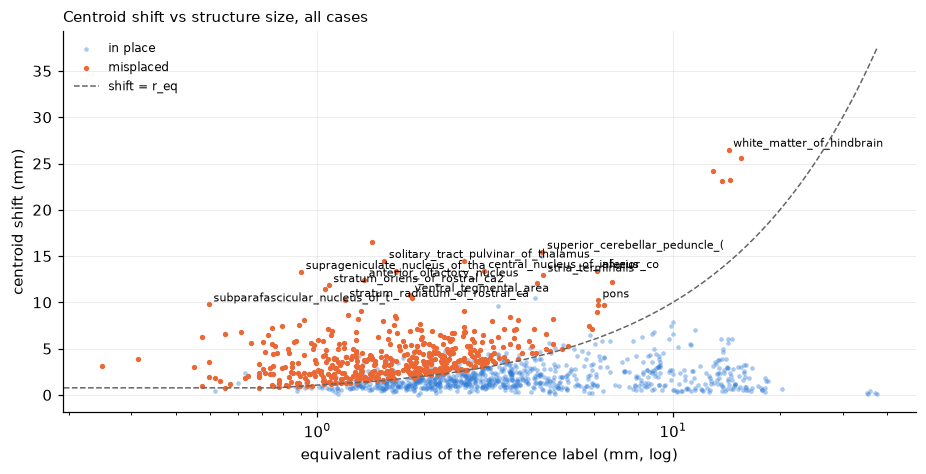

In [11]:
# systematic shift? centroid displacement vector (pred - ref) of the labels > 1000 mm3, which are well segmented
d = labels[(labels.presence == 'both') & (labels.vol_ref_mm3 > 1000)].copy()
for a in 'xyz':
    d[f'd{a}'] = d[f'c_pred_{a}'] - d[f'c_ref_{a}']
display(Markdown('**Mean centroid displacement (mm) of the labels > 1000 mm³** - a global registration offset would show up here'))
display(d.groupby('case')[['dx', 'dy', 'dz', 'centroid_dist_mm']].agg(['mean', 'median']).round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
s = labels[labels.presence == 'both']
ax.scatter(s.r_eq_mm, s.centroid_dist_mm, s=9, alpha=0.4, color=C_REF, linewidths=0, label='in place')
m = s[s.misplaced]
ax.scatter(m.r_eq_mm, m.centroid_dist_mm, s=12, color=C_PRED, linewidths=0, label='misplaced')
r = np.linspace(0, s.r_eq_mm.max(), 50); ax.plot(r, r, color='0.4', lw=1, ls='--', label='shift = r_eq')
for _, row in m[m.centroid_dist_mm > 9].drop_duplicates('label').iterrows():
    ax.annotate(row['name'][:30], (row.r_eq_mm, row.centroid_dist_mm), fontsize=7, xytext=(3, 2), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('equivalent radius of the reference label (mm, log)'); ax.set_ylabel('centroid shift (mm)')
ax.legend(frameon=False, fontsize=8); ax.set_title('Centroid shift vs structure size, all cases', loc='left', fontsize=10)
plt.show()

## 7. Visual inspection

Helpers: the image is the synthetic input (`deterministic/images/case-N.nii.gz`). Label maps are coloured with the
NextBrain LUT. In the contour views the reference label is **blue** and the predicted label is **orange**; each view
cuts through the reference centroid (sagittal / coronal / axial, voxel axes = RAS).

In [12]:
_cache = {}
def vols(case):
    if case not in _cache:
        ref, pred, affine, _ = cs.load_case(case)
        img = np.asanyarray(nib.load(cs.paths(case)['img']).dataobj).astype(np.float32)
        img = img[..., 0] if img.ndim == 4 else img
        _cache.clear(); _cache[case] = (img, ref, pred, affine)
    return _cache[case]

LUT = np.full((max(NAMES) + 1, 3), 0.5)
for line in open(cs.SEG_DIR / 'case-1.nii.gz/lut.txt'):
    p = line.split()
    if p:
        LUT[int(p[0])] = np.array(p[2:5], float) / 255
LUT[0] = 0

def _plane(a, axis, idx):
    return np.take(a, idx, axis=axis).T          # rows = 2nd remaining axis, shown with origin='lower'

def _norm(im):
    lo, hi = np.percentile(im[im > 0], [1, 99]) if (im > 0).any() else (0, 1)
    return np.clip((im - lo) / (hi - lo + 1e-6), 0, 1)

def show_label(case, label, pad_mm=12, title=None):
    img, ref, pred, affine = vols(case)
    mr, mp = ref == label, pred == label
    pts = np.argwhere(mr) if mr.any() else np.argwhere(mp)
    c = np.round(pts.mean(0)).astype(int)
    both = np.argwhere(mr | mp)
    pad = int(pad_mm / 0.4)
    lo, hi = np.maximum(both.min(0) - pad, 0), np.minimum(both.max(0) + pad, np.array(ref.shape) - 1)
    fig, axes = plt.subplots(3, 3, figsize=(12, 11))
    for col, (axis, view) in enumerate([(0, 'sagittal'), (1, 'coronal'), (2, 'axial')]):
        keep = [a for a in range(3) if a != axis]
        sl = [slice(None)] * 3
        sl[keep[0]] = slice(lo[keep[0]], hi[keep[0]] + 1); sl[keep[1]] = slice(lo[keep[1]], hi[keep[1]] + 1)
        sl[axis] = c[axis]
        im, r, p = img[tuple(sl)].T, ref[tuple(sl)].T, pred[tuple(sl)].T
        ax = axes[0, col]
        ax.imshow(_norm(im), cmap='gray', origin='lower')
        ax.contour(r == label, [0.5], colors=[C_REF], linewidths=1.6)
        ax.contour(p == label, [0.5], colors=[C_PRED], linewidths=1.6)
        ax.set_title(f'{view} (slice {c[axis]})  blue=ref  orange=pred', fontsize=8, loc='left')
        for row, (lab, nm) in enumerate([(r, 'ref'), (p, 'pred')], start=1):
            ax = axes[row, col]
            ax.imshow(_norm(im), cmap='gray', origin='lower')
            ax.imshow(LUT[lab], origin='lower', alpha=0.55)
            ax.contour(lab == label, [0.5], colors=['white'], linewidths=1.2)
            ax.set_title(f'{nm} labels (white = {label})', fontsize=8, loc='left')
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    row = labels[(labels.case == case) & (labels.label == label)].iloc[0]
    fig.suptitle(title or (f'case {case} - {label} {NAMES.get(label, "?")}:  dice {row.dice:.2f}, '
                           f'vol ref {row.vol_ref_mm3:.0f} / pred {row.vol_pred_mm3:.0f} mm³, shift {row.centroid_dist_mm:.1f} mm, '
                           f'ref -> {row.ref_to_pred_name} ({row.ref_to_pred_frac:.0%})'), fontsize=9, x=0.01, ha='left')
    plt.tight_layout(); plt.show()

### 7.1 Cerebellar white matter: 611 (reference) vs 846 (NextBrain)

Top row: contours of 611 in both maps - blue (reference) covers the cerebellar and the brainstem white matter, orange
(prediction) only the brainstem part. Bottom rows: the cerebellar white matter is the same tissue in both maps, only
the id differs (846 in the prediction).

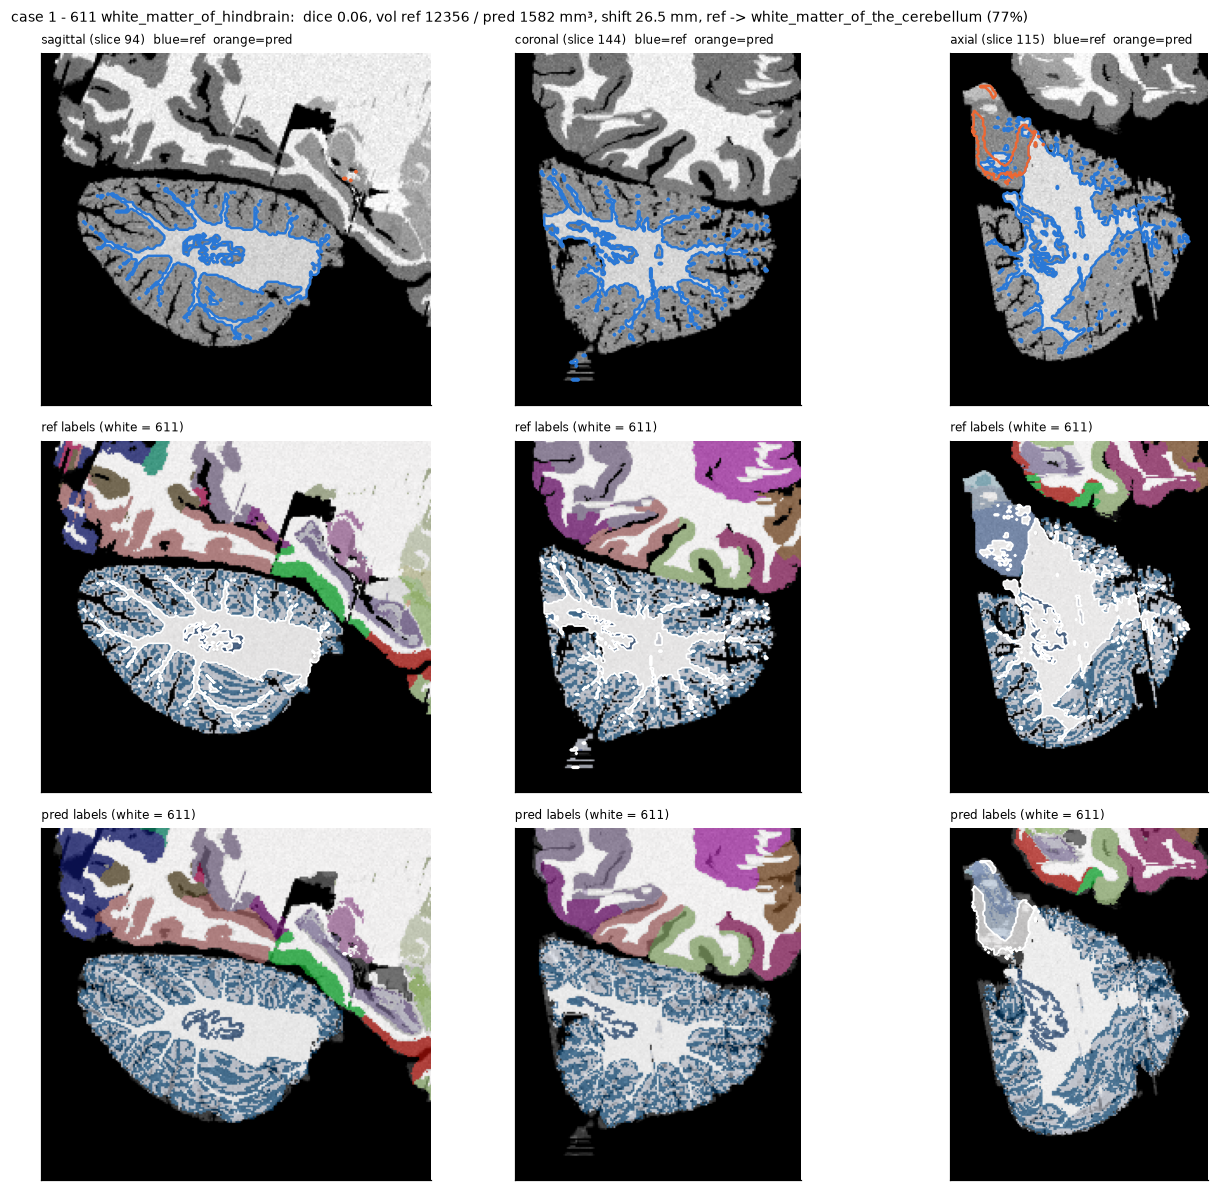

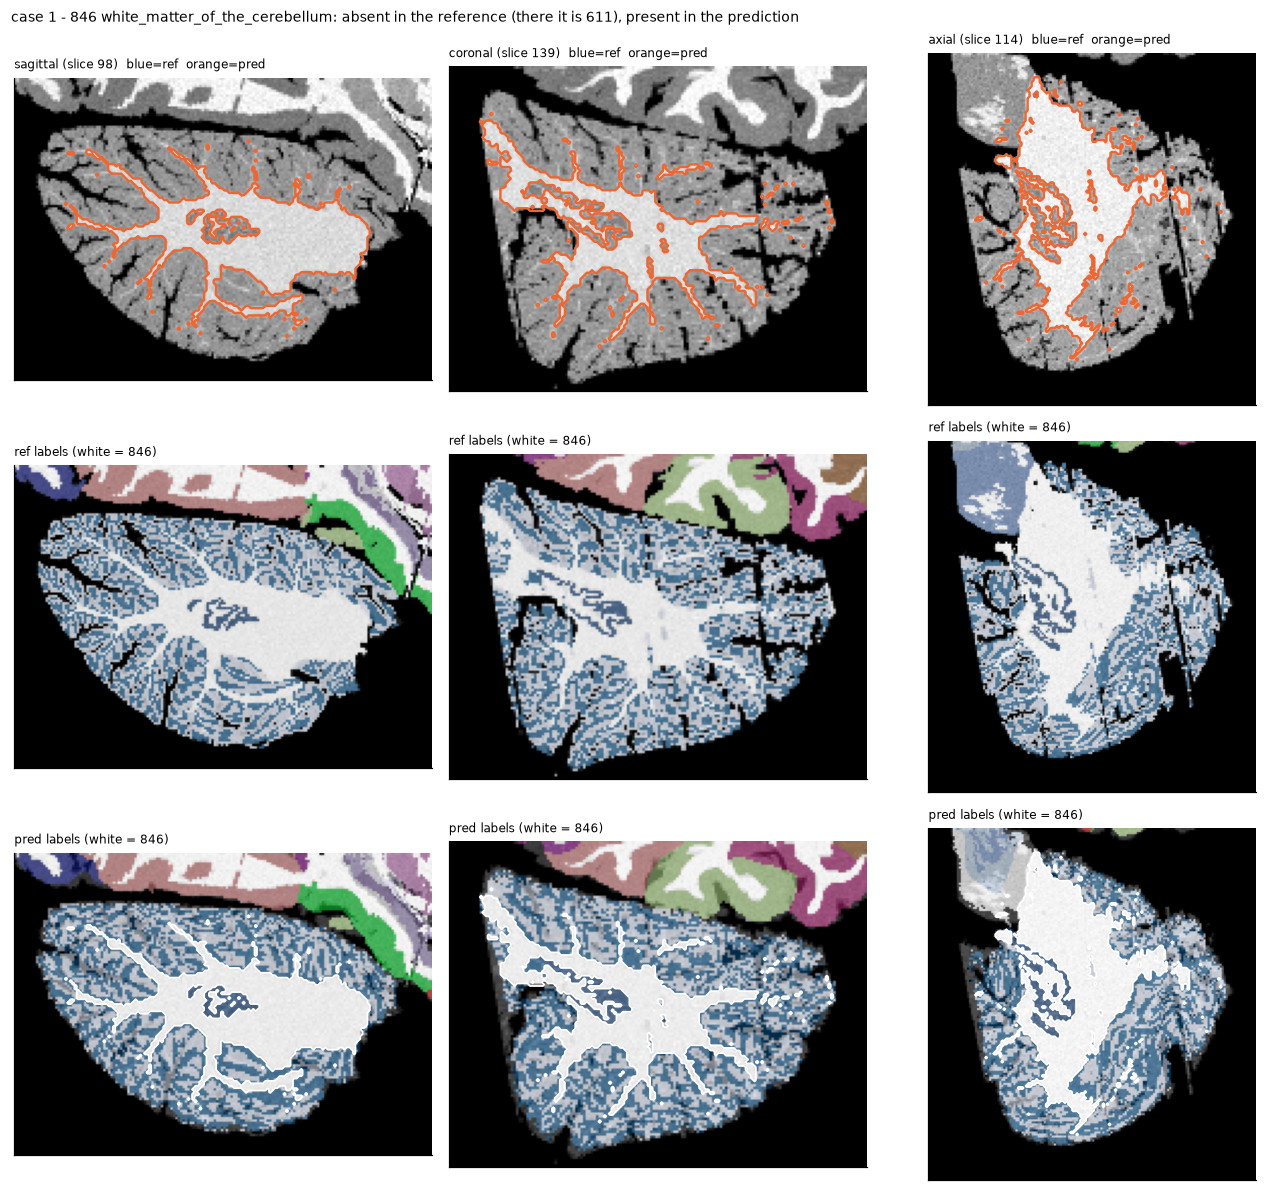

In [13]:
show_label(1, 611, pad_mm=5)
show_label(1, 846, pad_mm=5, title='case 1 - 846 white_matter_of_the_cerebellum: absent in the reference (there it is 611), present in the prediction')

### 7.2 Labels misplaced in every case

The largest labels that are misplaced in all 5 cases (excluding 611, explained above), shown on case 1.

,label,name,vol_ref,vol_pred,dice,shift_mm,goes_to,comes_from
1,184,stria_terminalis,314.842,82.189,0.018,9.660,background,body_of_caudate
2,68,septum_pellucidum,248.986,7.309,0.034,4.778,background,white_matter_of_forebrain
3,654,inferior_olive__principal_nucleus,159.949,4.147,0.006,5.748,myelencephalon_(medulla_oblongata),myelencephalon_(medulla_oblongata)
4,381,ventral_subdivision_of_vlc,120.461,96.512,0.011,4.607,lateral_posterior_nucleus_of_thalamus,parvocellular_division_of_va
5,666,facial_nucleus,76.339,1.126,0.002,4.133,white_matter_of_hindbrain,pontine_nucleus
6,382,medial_subdivision_of_vlc_(area_x),70.950,85.734,0.002,4.059,lateral_posterior_nucleus_of_thalamus,parvocellular_division_of_va


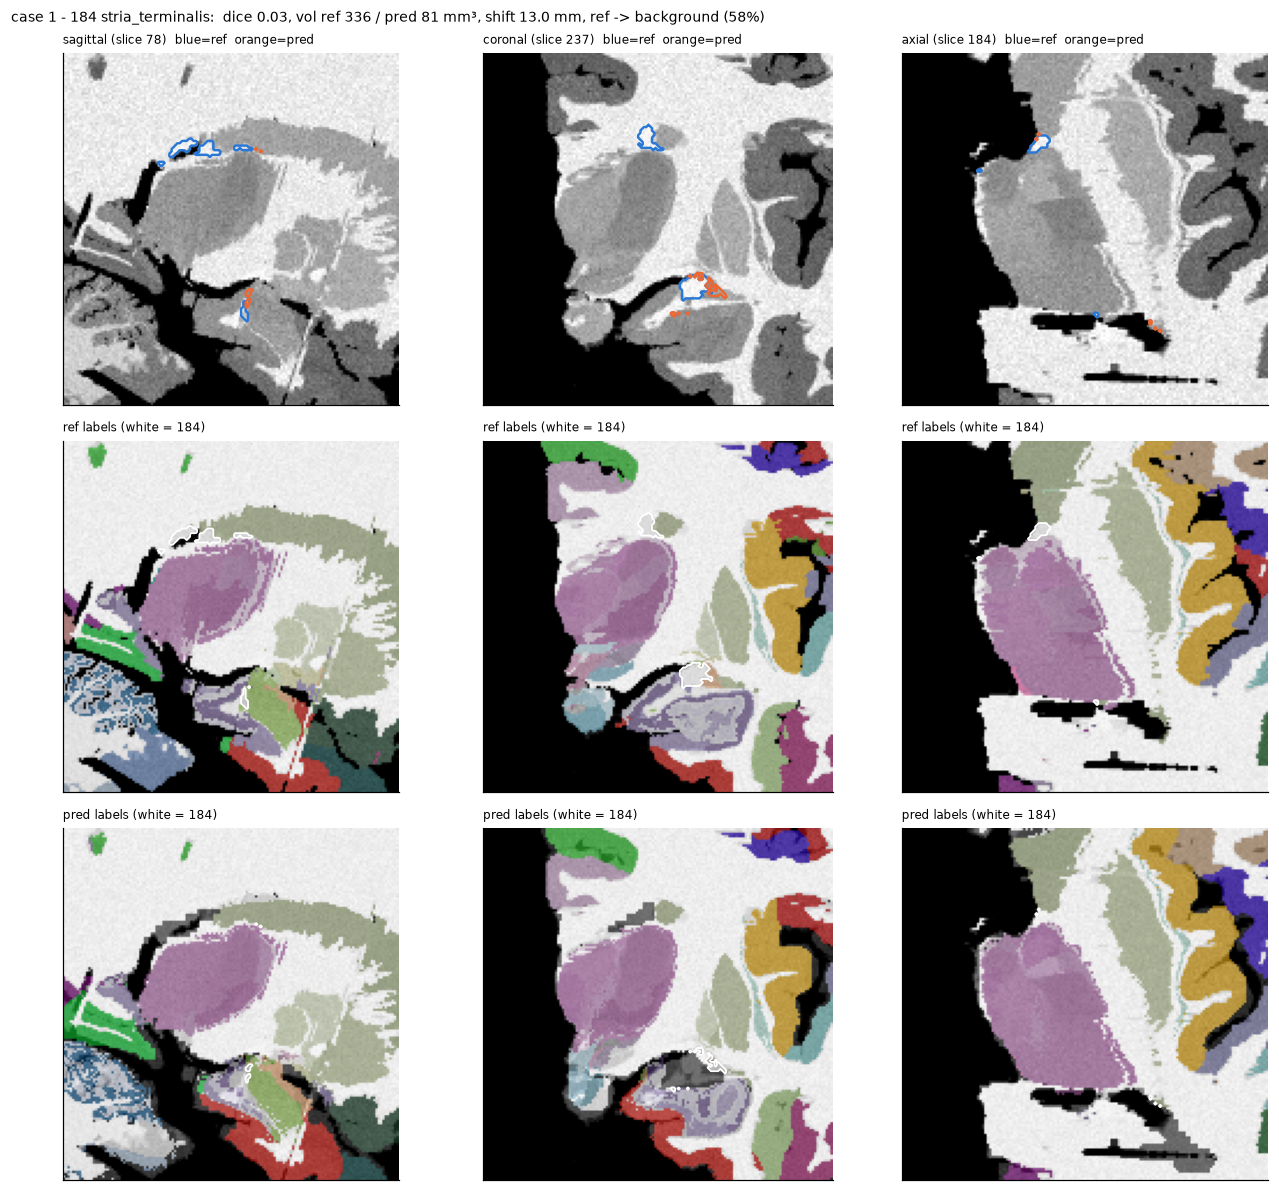

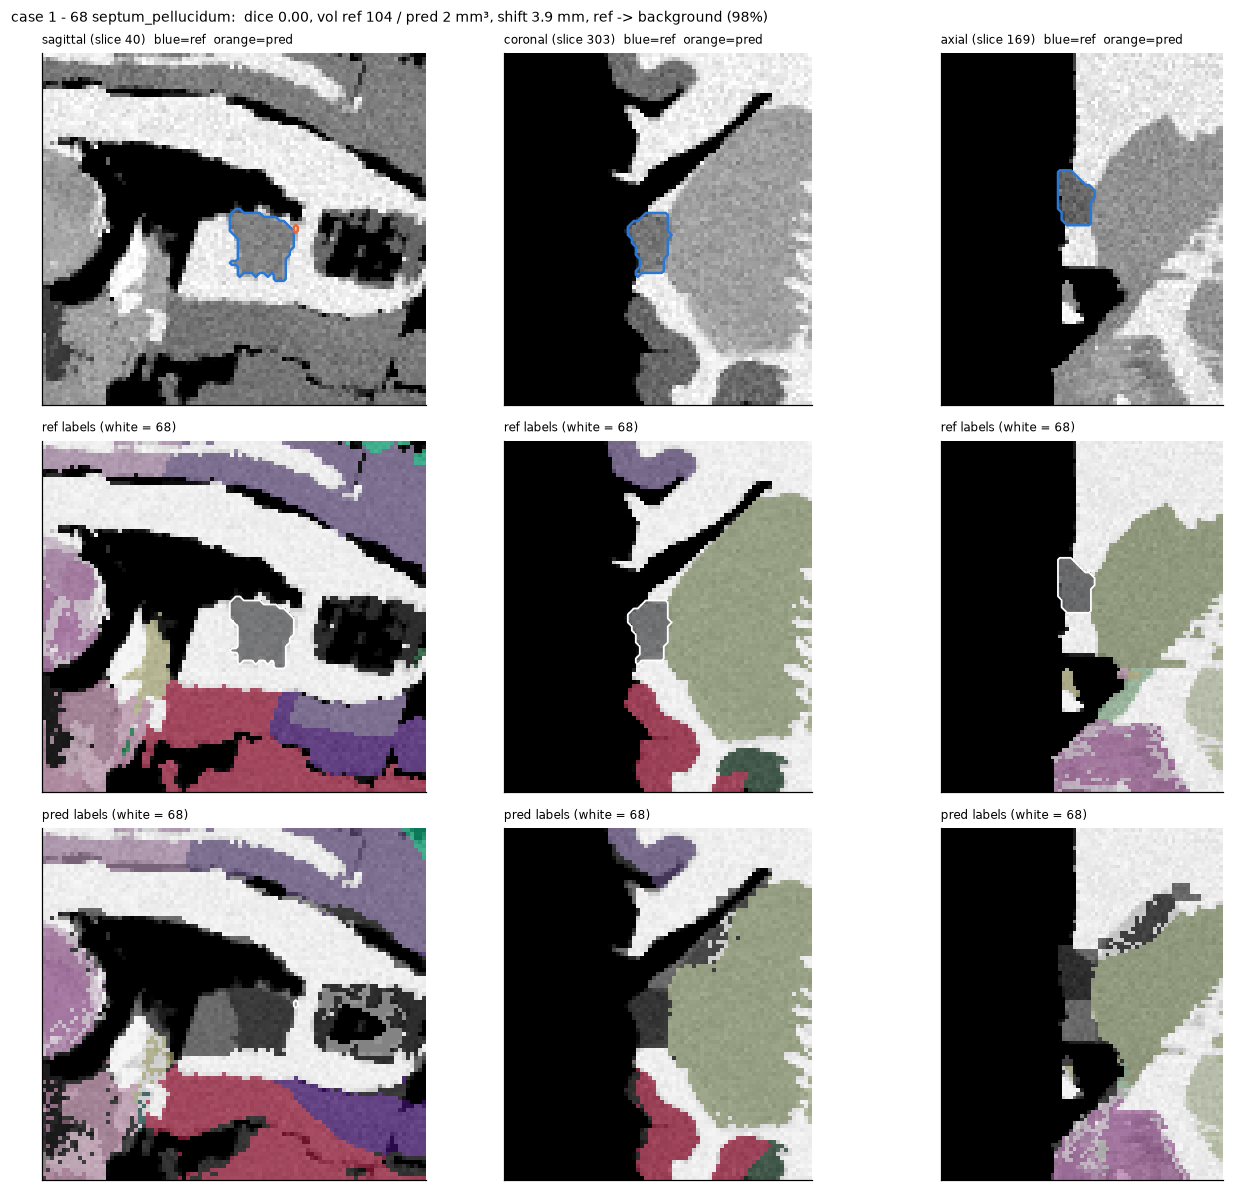

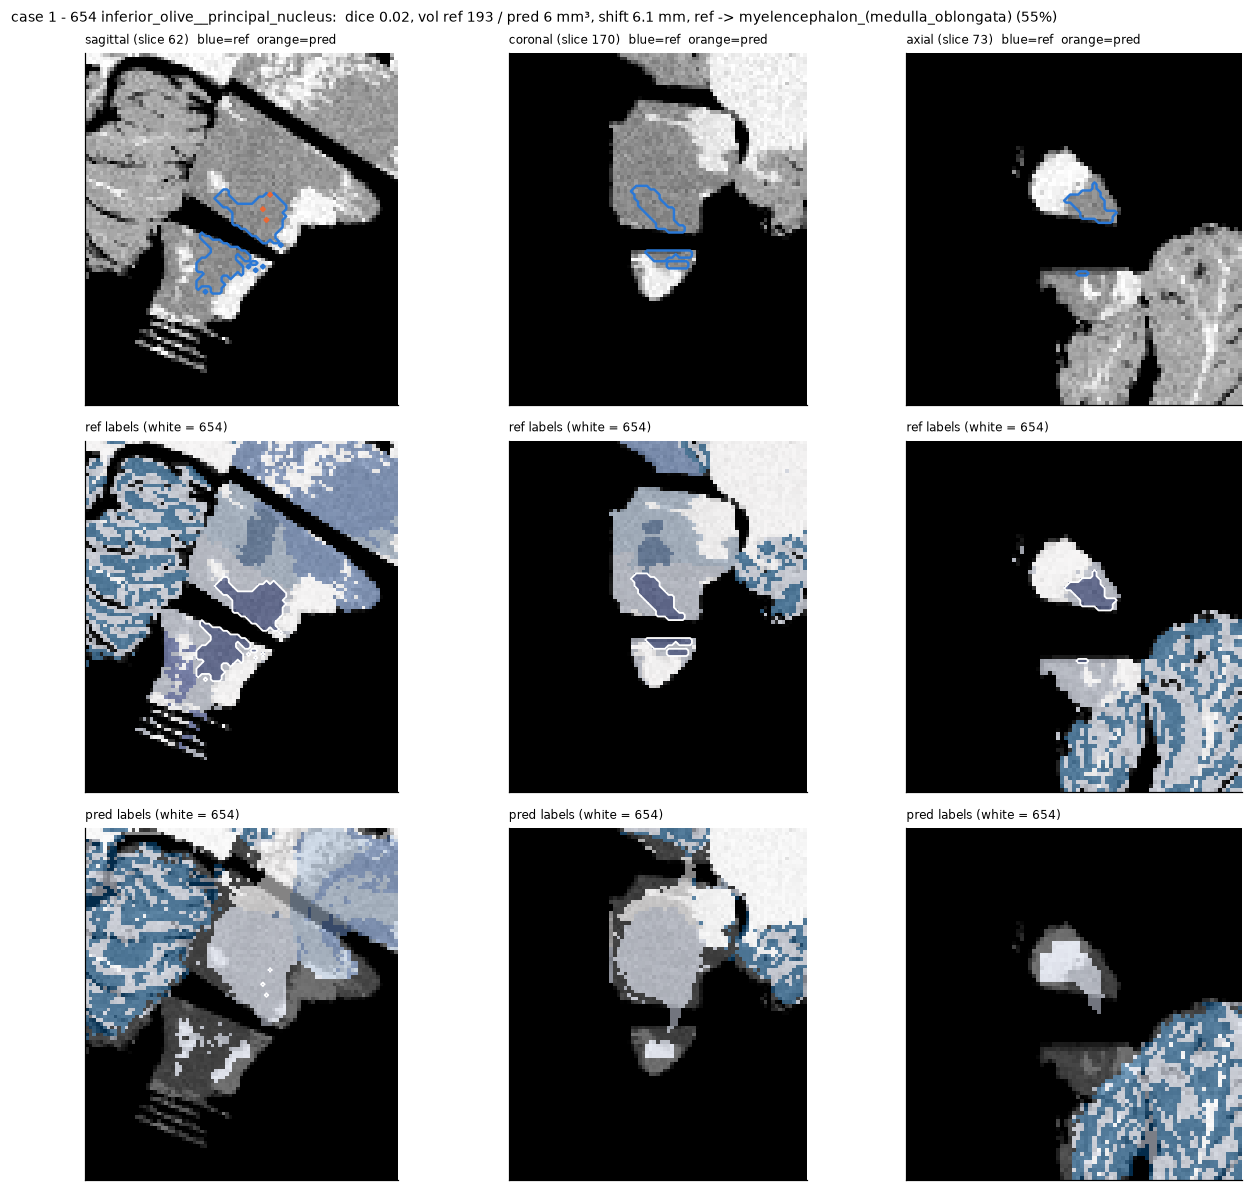

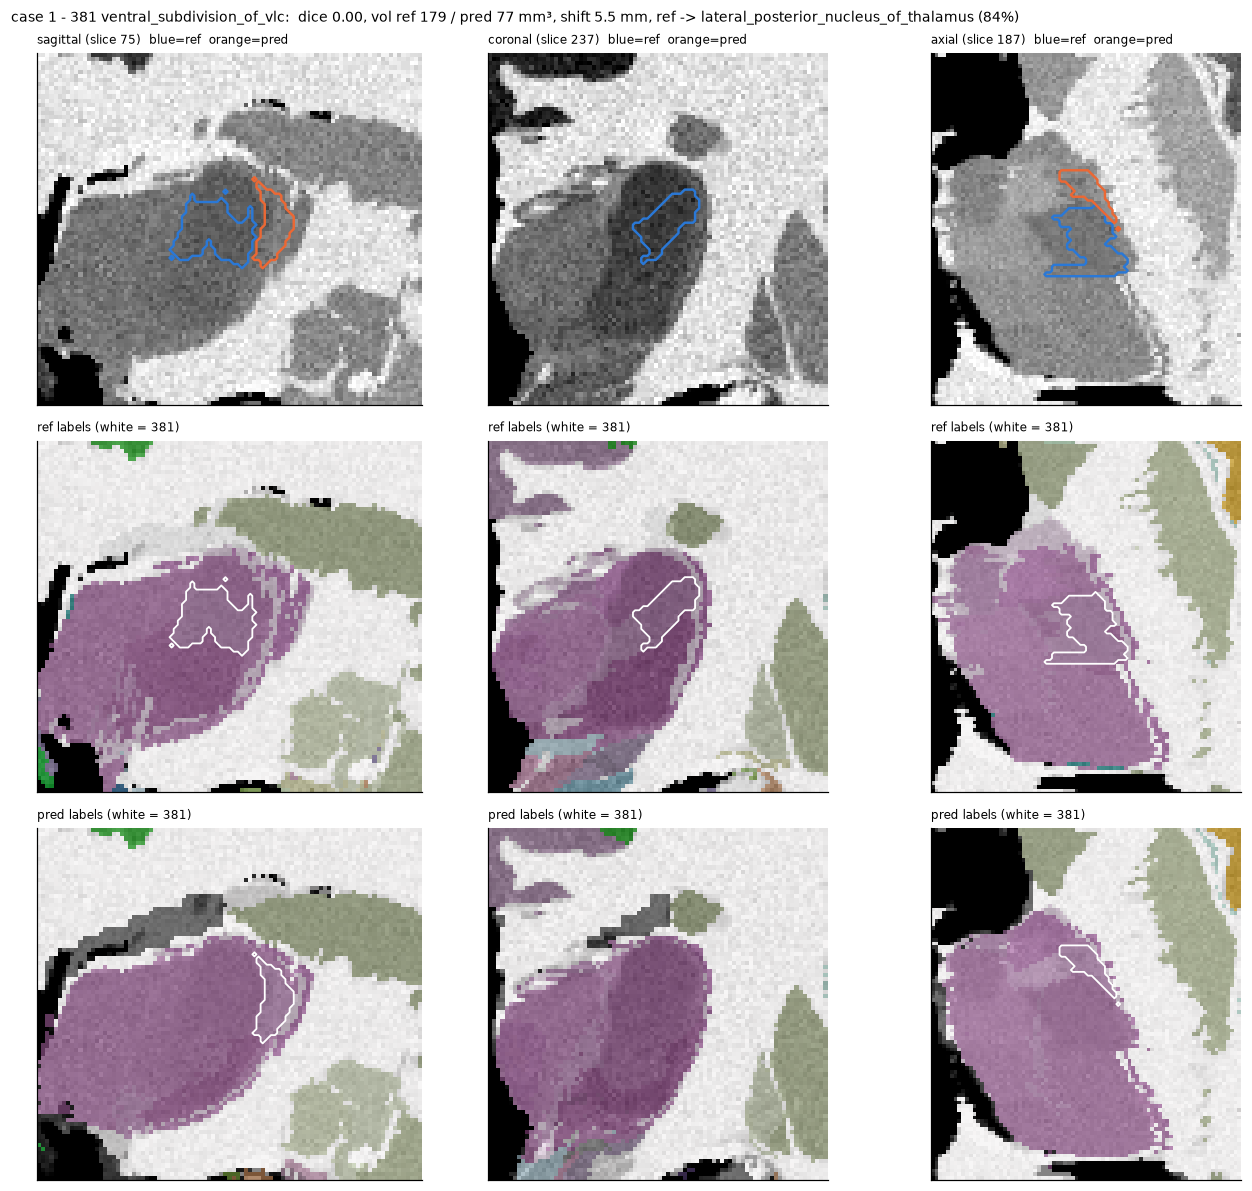

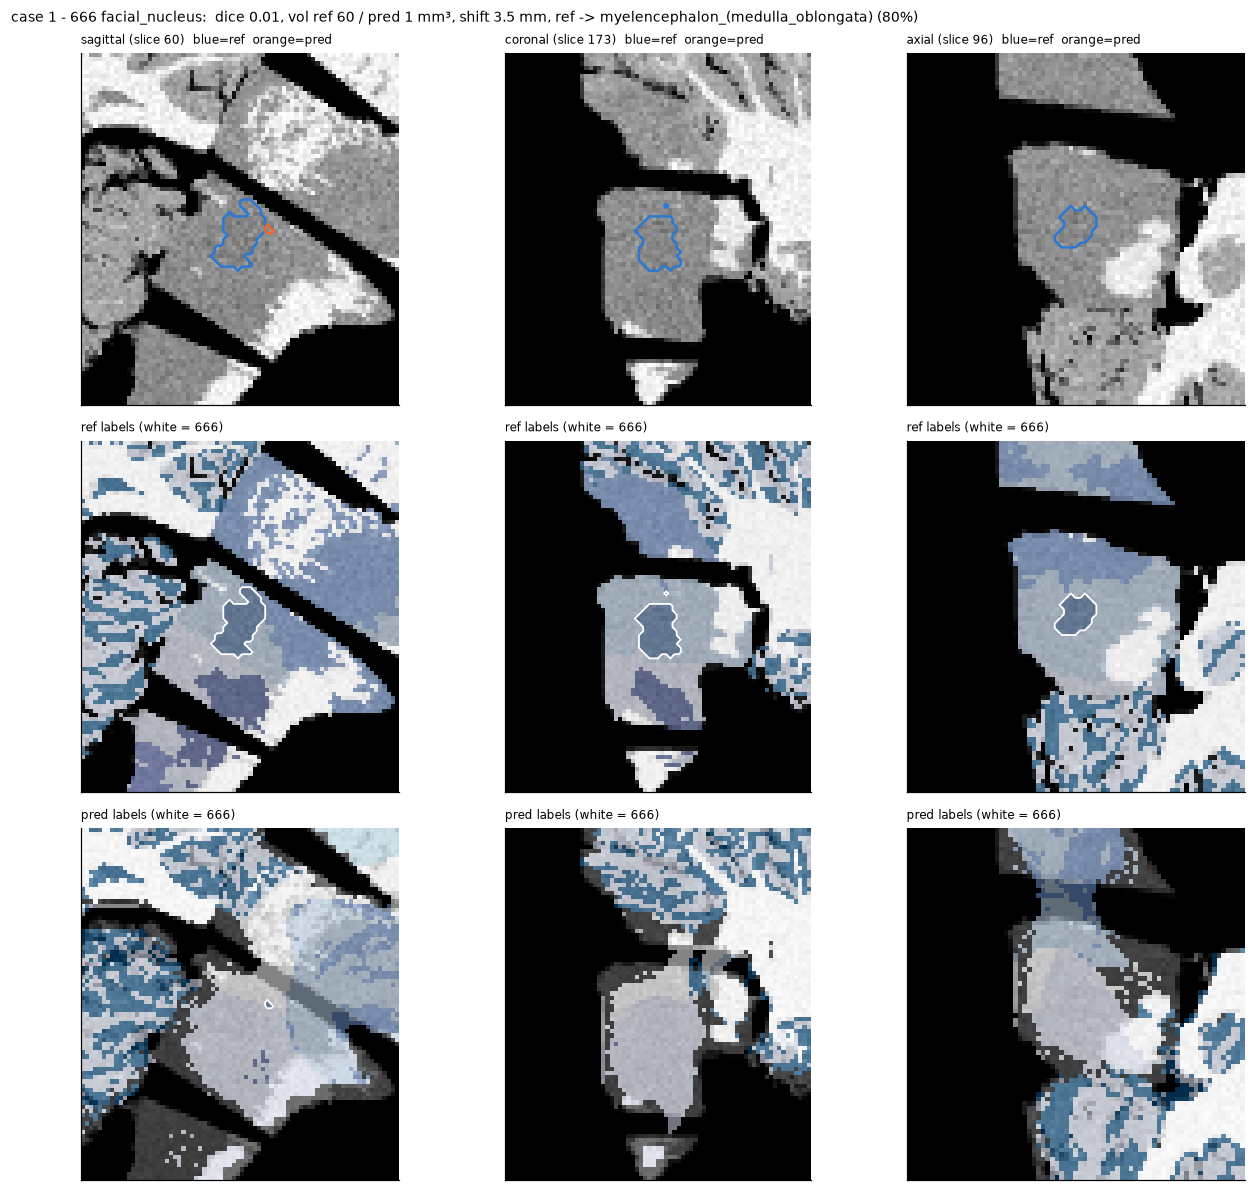

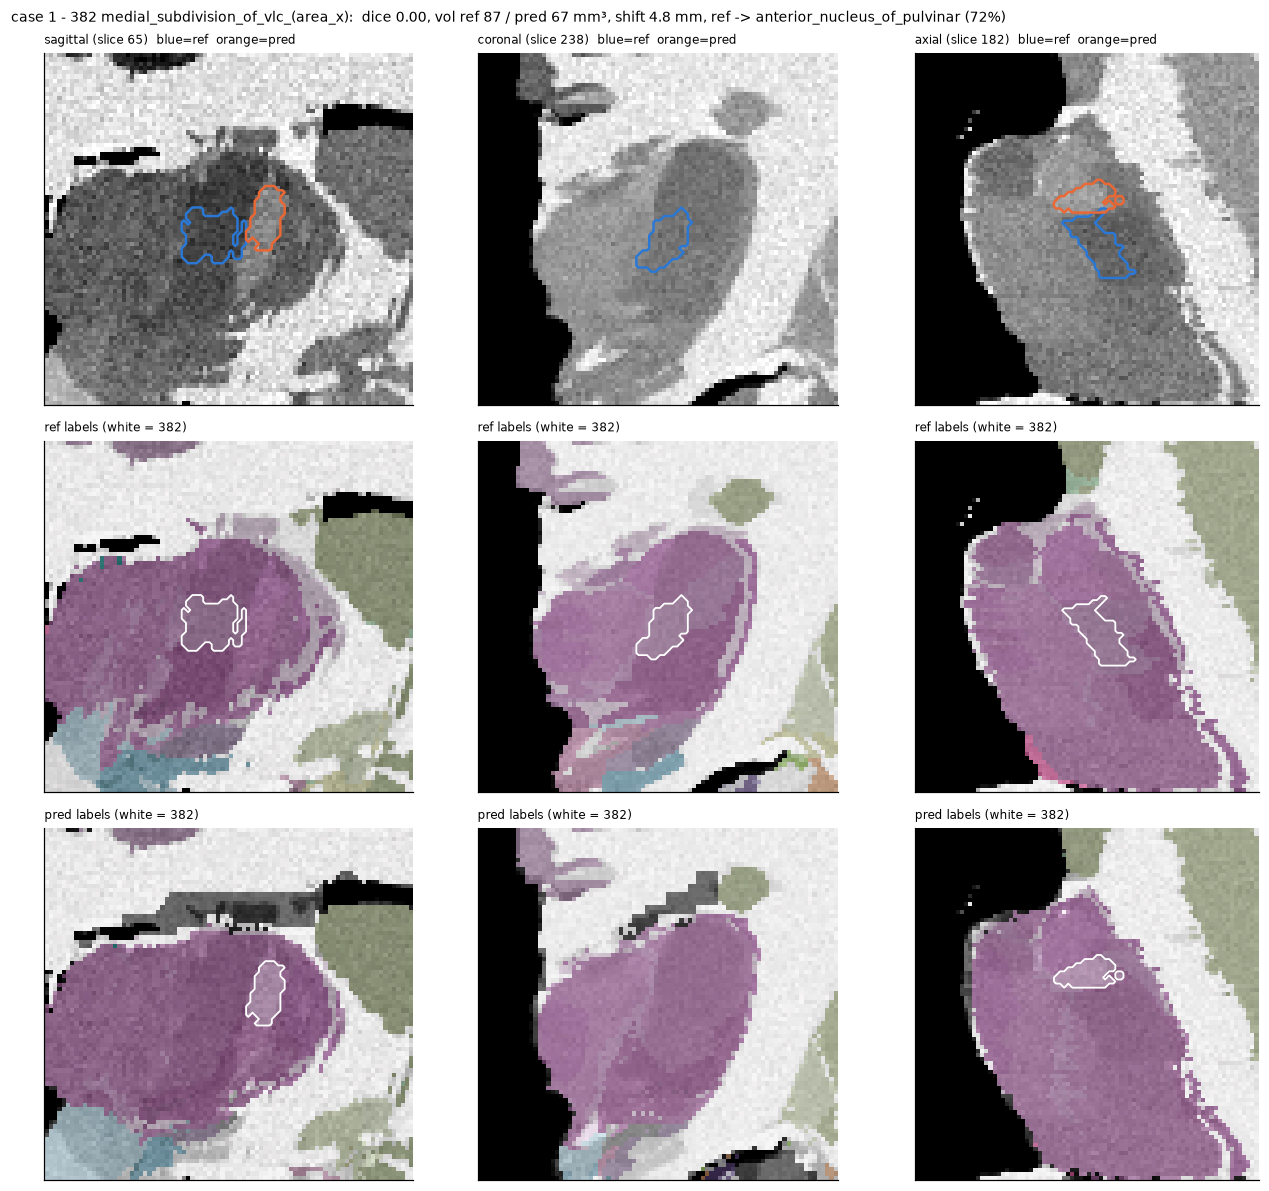

In [14]:
worst = mp[(mp.n_cases == 5)].reset_index()
worst = worst[worst.label != 611].head(6)
display(worst[['label', 'name', 'vol_ref', 'vol_pred', 'dice', 'shift_mm', 'goes_to', 'comes_from']])
for lab in worst.label:
    show_label(1, int(lab))

### 7.3 Labels only in the reference (largest instance of each)

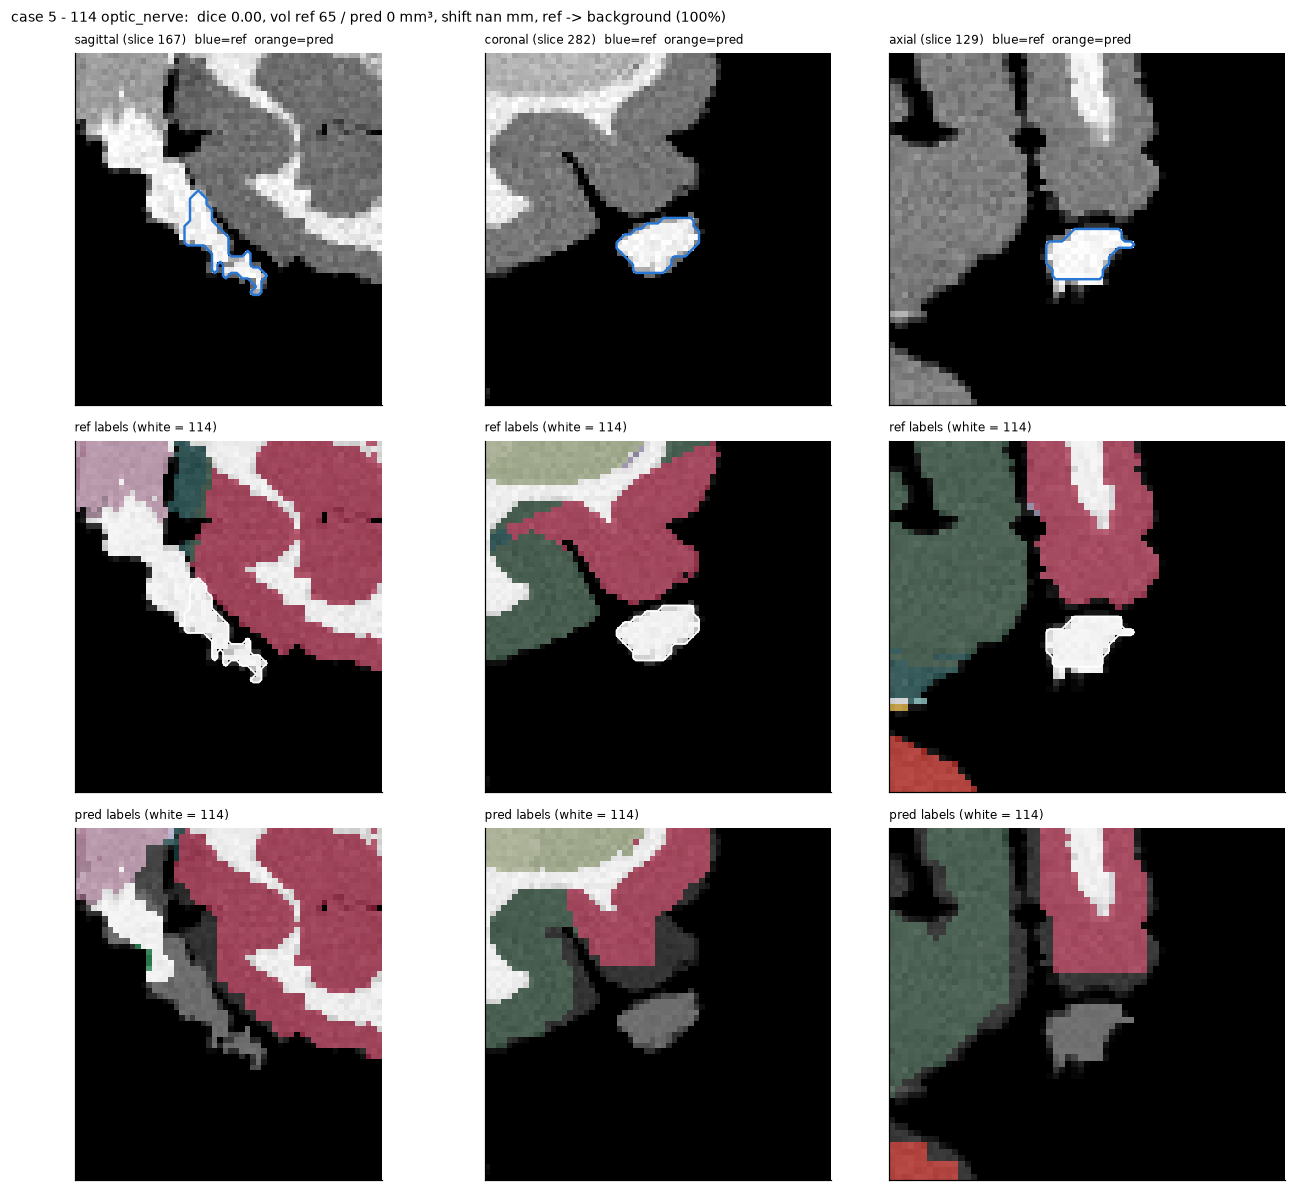

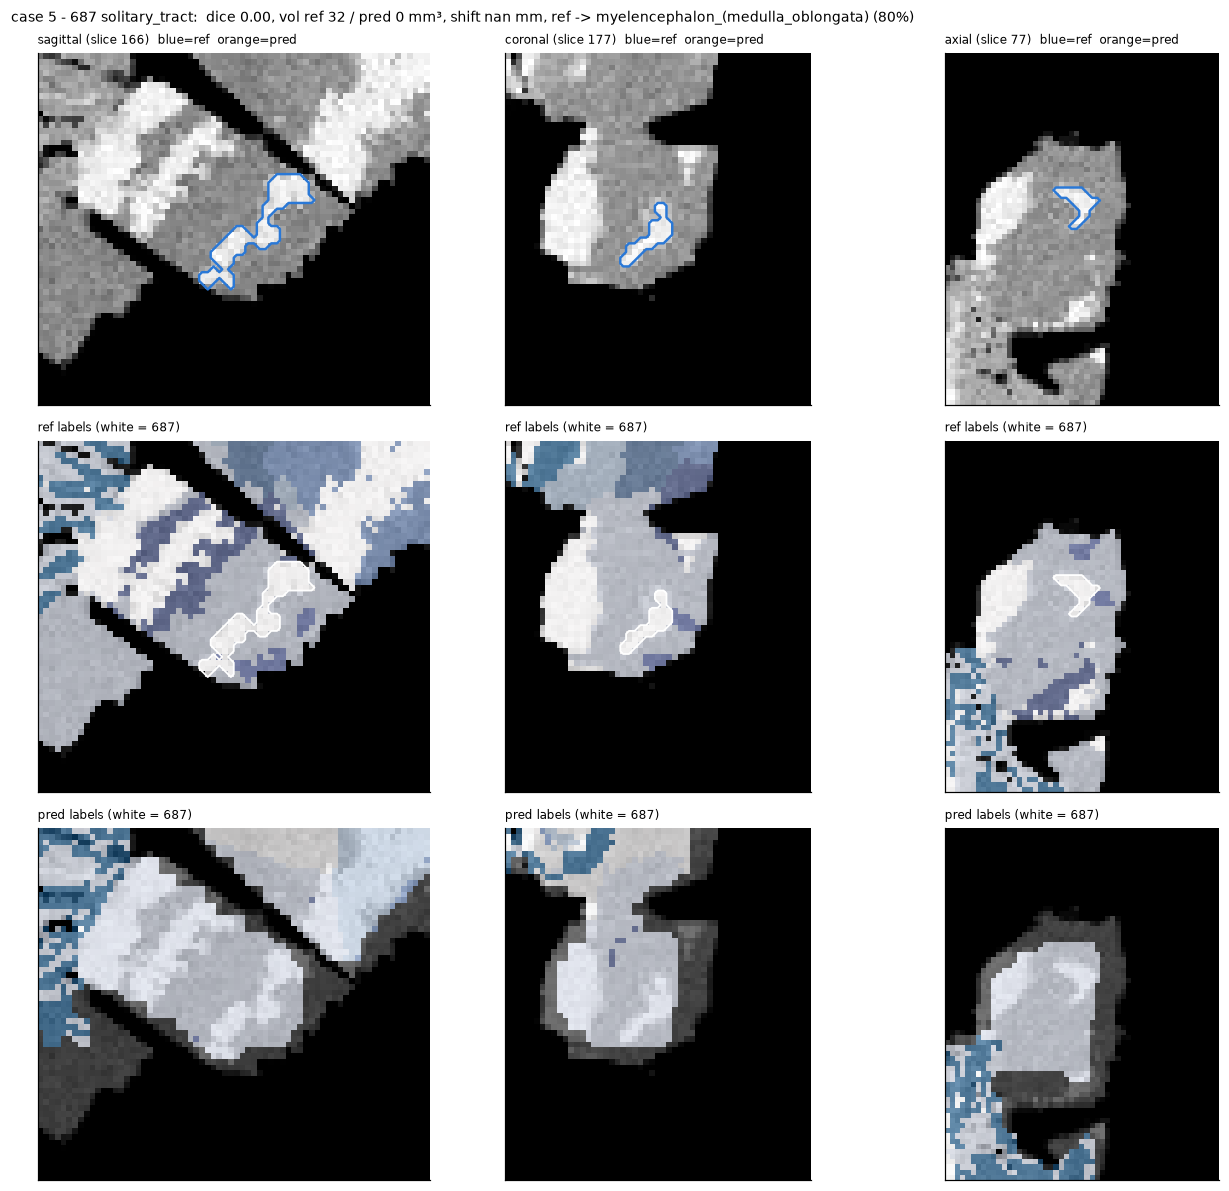

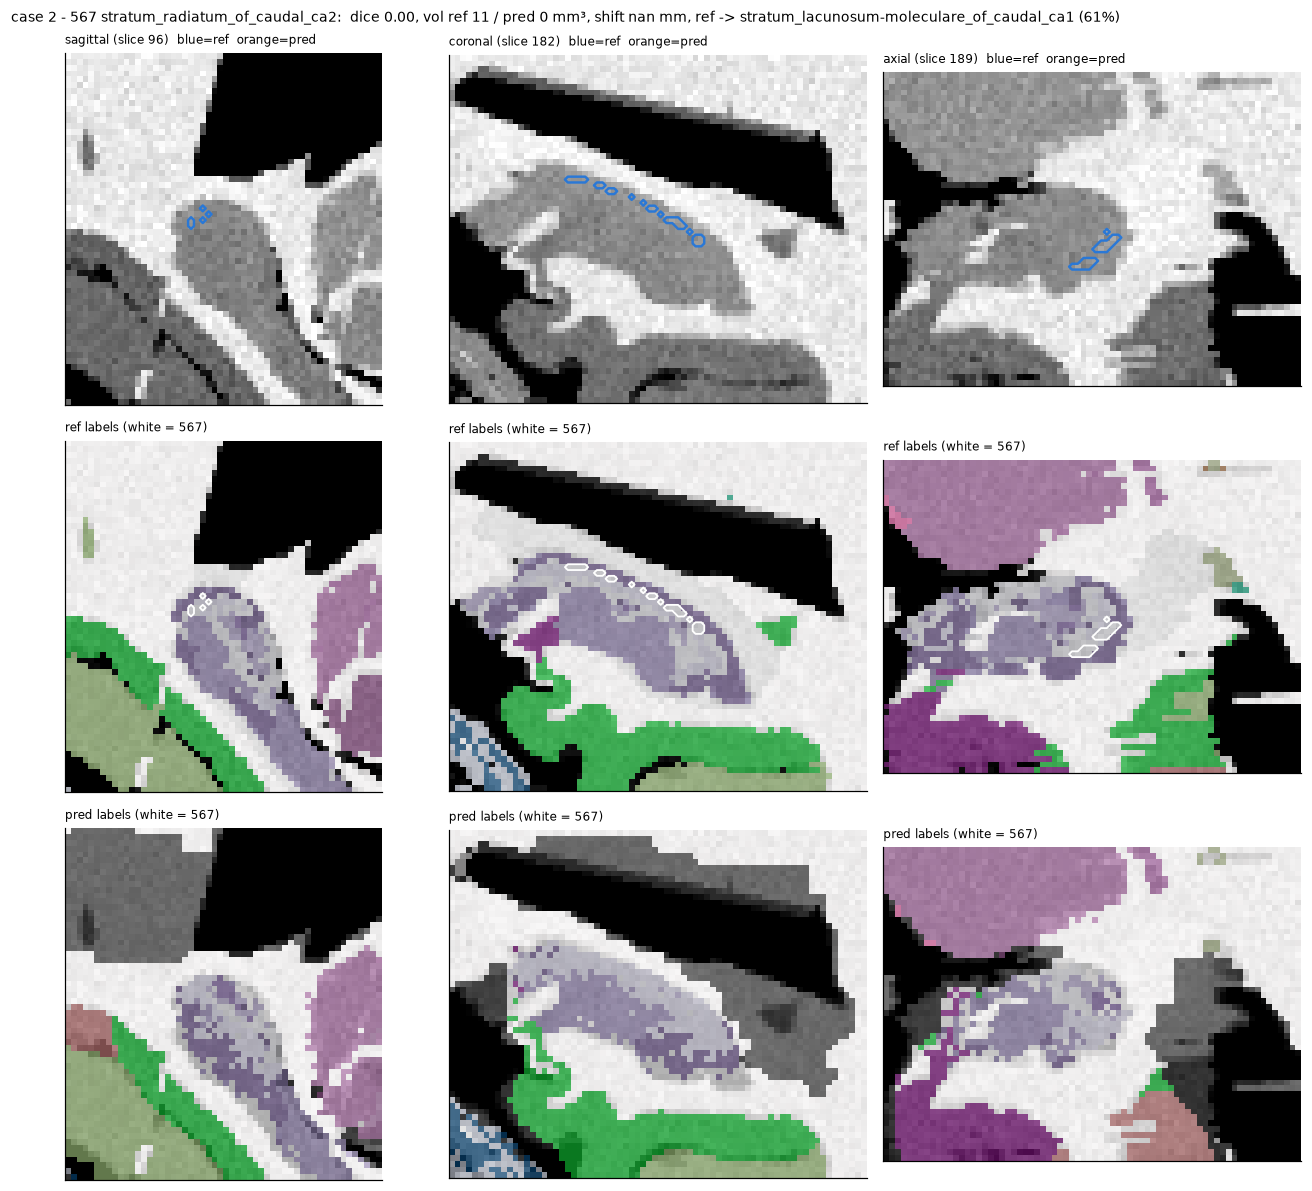

In [15]:
only_ref = presence[presence.presence == 'only_ref'].sort_values('vol_ref_mm3', ascending=False).drop_duplicates('label').head(3)
for _, r in only_ref.iterrows():
    show_label(int(r.case), int(r.label), pad_mm=8)

### 7.4 Where the two maps disagree (whole hemisphere)

For each case: a sagittal, coronal and axial slice through the centre of the brain with the voxels where `ref != pred`
in orange (only the foreground of either map). Here 846 in the prediction is first renamed to 611 so that the id
convention of section 5 does not paint the whole cerebellar white matter. Disagreement concentrates on thin structures and boundaries
(cortex/background boundary, hippocampal layers, thalamic and brainstem nuclei) and on the cerebellar cortex, where
the molecular (595) and granular (597) layers of the cerebellar cortex are mixed almost 50/50 (NextBrain does not separate them).

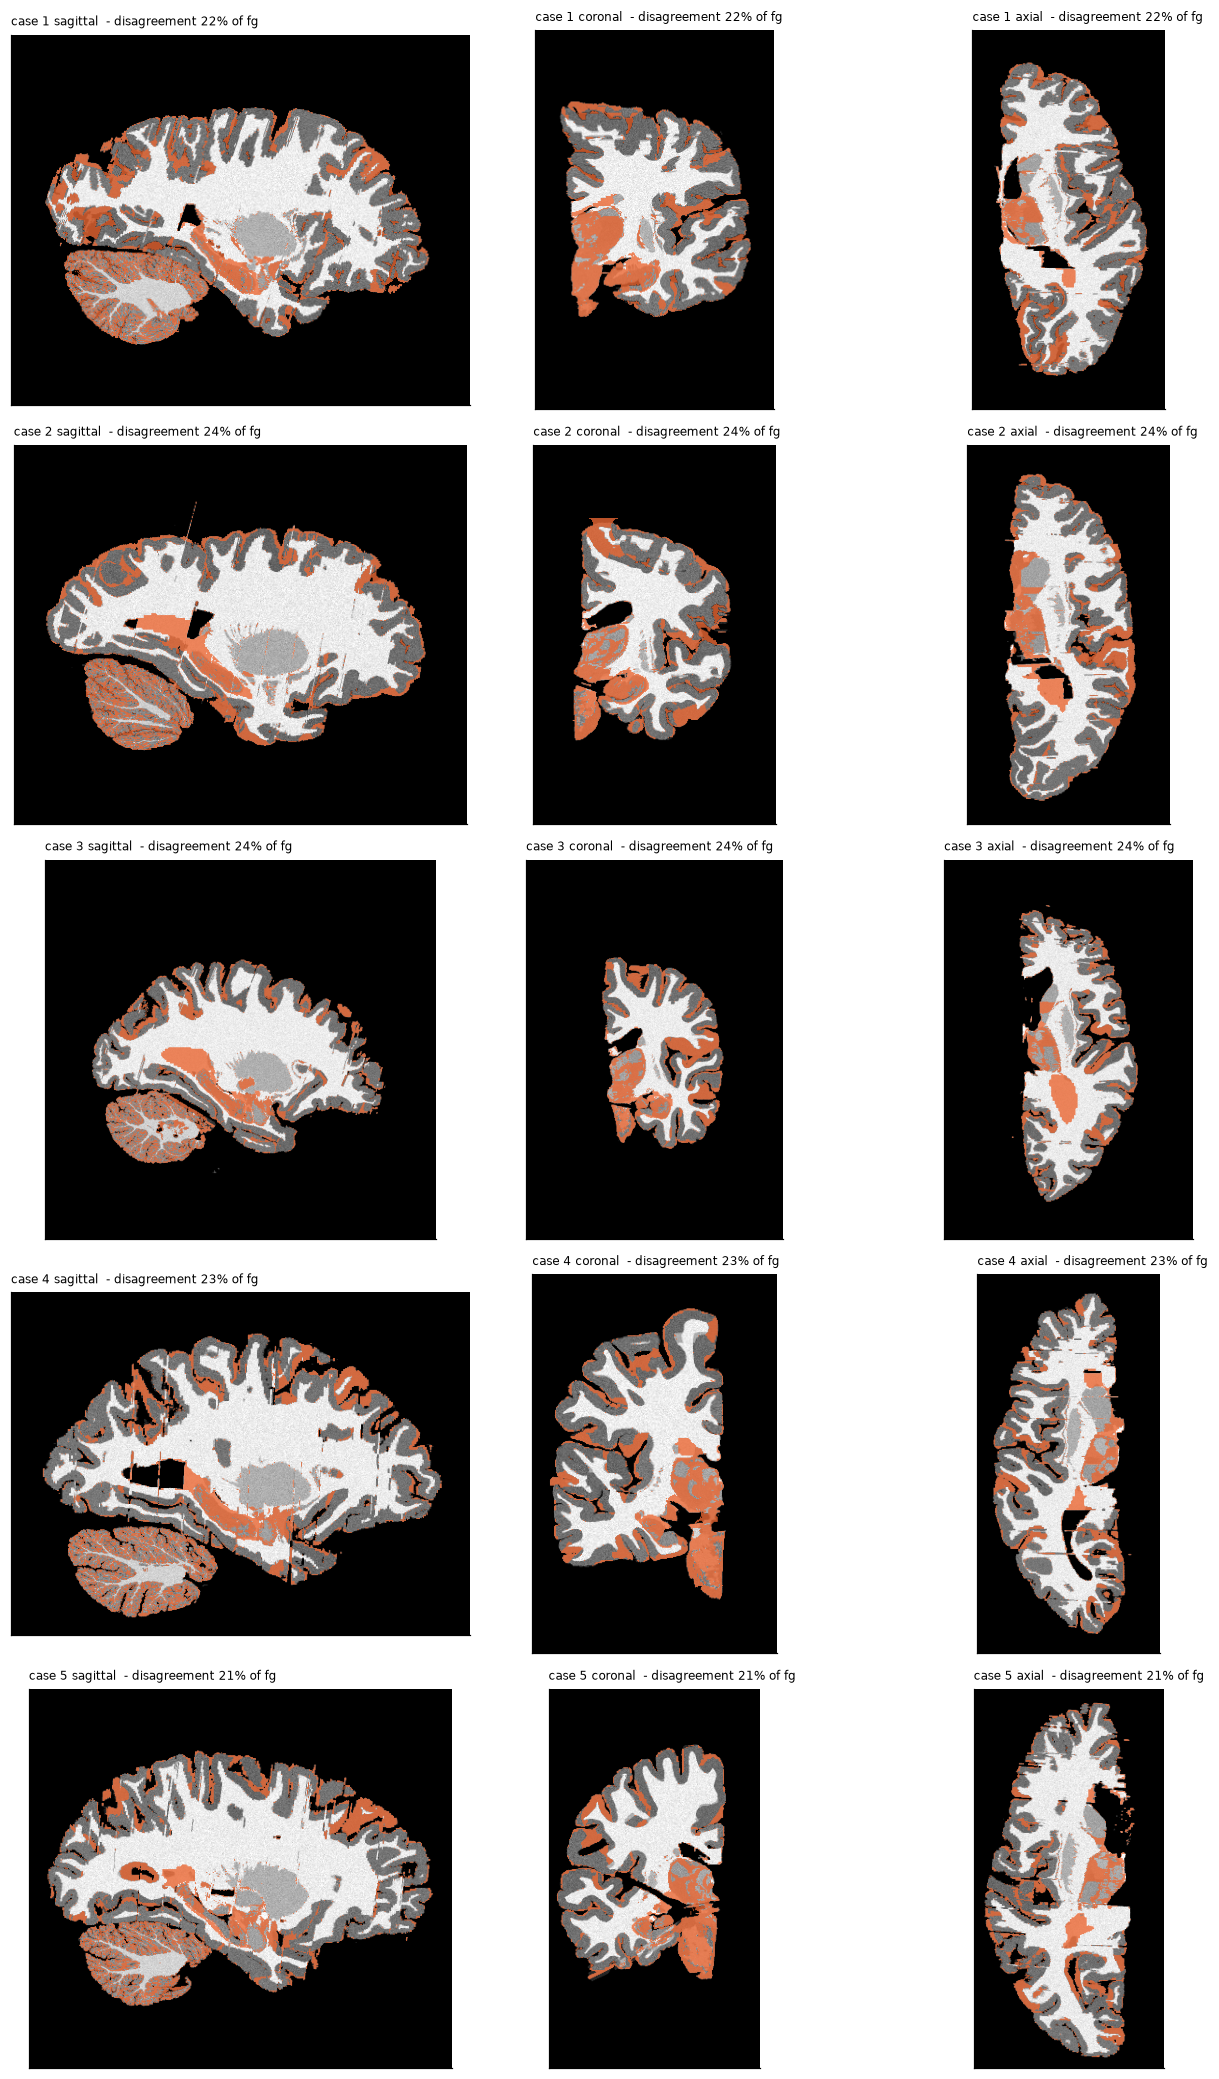

In [16]:
fig, axes = plt.subplots(5, 3, figsize=(12, 19))
for i, case in enumerate(cs.CASES):
    img, ref, pred, _ = vols(case)
    fgm = (ref > 0) | (pred > 0)
    c = np.round(np.argwhere(fgm).mean(0)).astype(int)
    err = fgm & (ref != np.where(pred == 846, 611, pred))
    for j, axis in enumerate(range(3)):
        ax = axes[i, j]
        ax.imshow(_norm(_plane(img, axis, c[axis])), cmap='gray', origin='lower')
        e = _plane(err, axis, c[axis])
        ax.imshow(np.ma.masked_where(~e, e), cmap=mcolors.ListedColormap([C_PRED]), origin='lower', alpha=0.8)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f'case {case} {["sagittal", "coronal", "axial"][j]}  - disagreement {err[fgm].mean():.0%} of fg',
                     fontsize=8, loc='left')
plt.tight_layout(); plt.show()

In [17]:
# share of the disagreeing voxels per (ref, pred) pair: which confusions dominate the error
e = conf[conf.ref != conf.pred].copy()
e['ref_name'] = e.ref.map(lambda x: NAMES.get(x, '?')); e['pred_name'] = e.pred.map(lambda x: NAMES.get(x, '?'))
tot_err = e.groupby('case').n.sum()
e['frac_of_case_error'] = e.n / e.case.map(tot_err)
top_err = (e.groupby(['ref', 'ref_name', 'pred', 'pred_name']).frac_of_case_error.mean()
           .sort_values(ascending=False).head(20).reset_index())
top_err.to_csv(METRICS / 'top_confusions.csv', index=False)
display(Markdown('**Top 20 confusions (mean fraction of all disagreeing voxels of a case)**'))
display(top_err)

**Top 20 confusions (mean fraction of all disagreeing voxels of a case)**

,ref,ref_name,pred,pred_name,frac_of_case_error
0,595,molecular_layer_of_pva,597,granular_cell_layer_of_pva,0.079
1,611,white_matter_of_hindbrain,846,white_matter_of_the_cerebellum,0.068
2,597,granular_cell_layer_of_pva,595,molecular_layer_of_pva,0.062
3,7,white_matter_of_forebrain,0,background,0.025
4,2028,ctx-rh-superiorfrontal,0,background,0.021
5,2024,ctx-rh-precentral,0,background,0.016
6,2027,ctx-rh-rostralmiddlefrontal,0,background,0.016
7,0,background,595,molecular_layer_of_pva,0.016
8,2022,ctx-rh-postcentral,0,background,0.013
9,2029,ctx-rh-superiorparietal,0,background,0.012


## 8. Conclusions

1. **Global agreement is good where the structures are large.** The brain outline matches (`brain_dice` 0.94-0.96), the
   forebrain white matter has dice ~0.97, the 34 cortical parcels ~0.75-0.87, and putamen/pallidum/caudate 0.87-0.93.
   At tree level 1 every tissue class except midbrain white matter has dice > 0.64 (most > 0.83). 75-78 % of the
   foreground voxels get the same label.
2. **Per-label dice is driven by size.** Median dice is ~0.01 for labels < 10 mm³, ~0.1 for 10-100 mm³, ~0.33 for
   100-1000 mm³ and ~0.75-0.8 above 1000 mm³. This is why the unweighted mean dice is only 0.26-0.31 while the
   volume-weighted dice is 0.78-0.81. There is no global registration offset: the centroids of the large labels move
   < 0.6 mm on average in every axis.
3. **Label-id convention 611 / 846 (cerebellar white matter).** The reference uses 611 for all hindbrain white matter;
   NextBrain uses 846 for the cerebellar white matter and 611 for the brainstem. This one difference produces the only
   large `only_pred` label (846, ~10 000 mm³), the most "misplaced" label (611, dice ~0.03, shift ~25 mm) and ~7 % of
   all disagreeing voxels. The tree already merges both ids in one leaf, so it is harmless after mapping labels to tree
   nodes (leaf dice ~0.8). When comparing label maps directly, map 846 -> 611 first.
4. **Cerebellar cortex layers.** The molecular (595) and granular (597) layers of the cerebellar cortex are the largest
   source of disagreement (~14 % of the disagreeing voxels, dice ~0.45-0.5): ~44 % of REF 595 is predicted 597 and ~42 %
   of REF 597 is predicted 595, so NextBrain does not separate the two layers in the synthetic image (section 7.4).
5. **Labels only in one map.** Apart from 846, all differences are small labels (< 65 mm³) that NextBrain absorbs into a
   neighbour or the background. The repeated ones are `interstitial_nucleus_of_cajal` (5/5 cases),
   `stratum_oriens_of_caudal_ca2` (4/5) and `optic_nerve` (3/5), plus CA2/CA3 layers, `pineal_body` and
   `suprachiasmatic_nucleus` in 2 cases. They are candidates to add to `labels_to_remove.json` or to merge with their
   neighbour. NextBrain predicts only a few voxels of labels that are missing from the reference.
6. **Misplaced labels.** 77-114 labels per case are misplaced (dice < 0.2 and centroid outside the structure's
   equivalent sphere), but they are small: 15-23 cm³ in total per case, most of it 611. Excluding 611, the labels
   that are misplaced in **all 5 cases** and are not tiny are:
   `stria_terminalis` (~315 mm³, NextBrain puts it on the ventricle border/background), `septum_pellucidum` (~250 mm³,
   almost absent in the prediction), `inferior_olive__principal_nucleus` (~160 mm³, absorbed by the medulla),
   the VLc subdivisions (`ventral_subdivision_of_vlc`, `medial_subdivision_of_vlc_(area_x)`, predicted as
   lateral posterior / VA nuclei), `facial_nucleus`, `dorsal_medial_geniculate_nucleus`,
   `ventral_posterior_medial_nucleus` and `ventral_tegmental_area`. They are thalamic, brainstem and periventricular
   structures where the synthetic image probably has little contrast between neighbours. No pair of labels is swapped
   (`mutual_swaps.csv` is empty): misplaced labels are absorbed by a neighbour or by a parent class, not exchanged.
7. **Volumes.** The total labelled volume of the prediction is 0-9 % smaller than the reference (cases 2-5 lose
   cortex/white-matter voxels at the outer boundary to background). Among labels > 50 mm³, NextBrain makes the pulvinar
   nuclei (anterior +240 %, medial +120 %), `pons` (+90 %) and `lateral_posterior_nucleus_of_thalamus` (+87 %) larger, and
   `facial_nucleus`, `inferior_olive`, `septum_pellucidum`, `substantia_innominata` and `medial_septal_nucleus` much
   smaller (-84 to -99 %). These are the same structures as in point 6: the absorbing neighbours grow.